# 환경 설정


## 한글화 코드


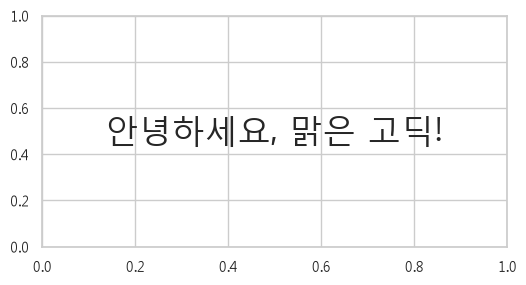

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 스타일을 먼저 적용
sns.set_theme(style="whitegrid")

# Windows 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 한글 표시 확인
plt.figure(figsize=(6, 3))
plt.text(
    0.5, 0.5,
    "안녕하세요, 맑은 고딕!",
    ha="center",
    va="center",
    size=24
)
plt.show()

## MySQL 연결


In [2]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine, URL, text

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("MySQL 비밀번호: "),
    host="localhost",
    port=3306,
    database="final",
    query={"charset": "utf8mb4"},
)

engine = create_engine(url, pool_pre_ping=True)

# 연결 확인
with engine.connect() as conn:
    print(conn.execute(text("SELECT VERSION()")).scalar())

8.0.37


## DataFrame에 저장


In [3]:
import pandas as pd
from sqlalchemy import text

params = {
    "start_at": "2023-05-04 00:00:00",
    "end_at": "2024-05-06 00:00:00",
}

queries = {
    "polls_question": """
        SELECT
            id,
            TRIM(question_text) AS question_text,
            created_at
        FROM final.polls_question
    """,

    "polls_questionreport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            question_id,
            user_id
        FROM final.polls_questionreport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_usercandidate": """
        SELECT
            id,
            created_at,
            question_piece_id,
            user_id
        FROM final.polls_usercandidate
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionset": """
        SELECT
            id,
            question_piece_id_list,
            opening_time,
            status,
            user_id
        FROM final.polls_questionset
        WHERE opening_time >= created_at
          AND status = 'F'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionpiece": """
        SELECT
            id,
            is_voted,
            question_id,
            is_skipped
        FROM final.polls_questionpiece
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_userquestionrecord": """
        SELECT
            id,
            status,
            created_at,
            chosen_user_id,
            question_id,
            user_id,
            question_piece_id,
            has_read,
            answer_status,
            answer_updated_at,
            report_count,
            opened_times
        FROM final.accounts_userquestionrecord
        WHERE answer_status <> 'P'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    # 가입일 제한 없이 일반 유저 전체 조회
    "accounts_user": """
        SELECT
            id,
            is_superuser,
            is_staff,
            gender,
            friend_id_list,
            is_push_on,
            created_at,
            block_user_id_list,
            hide_user_id_list,
            ban_status,
            report_count,
            group_id
        FROM final.accounts_user
        WHERE is_superuser = 0
          AND is_staff = 0
    """,

    "accounts_timelinereport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            reported_user_id,
            user_id,
            user_question_record_id
        FROM final.accounts_timelinereport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_school": """
        SELECT
            id,
            student_count,
            school_type
        FROM final.accounts_school
    """,

    "accounts_group": """
        SELECT
            id,
            school_id
        FROM final.accounts_group
    """,

    "accounts_blockrecord": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            block_user_id,
            user_id
        FROM final.accounts_blockrecord
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    # 구매 기록: 전체 기간 조회 후 분석 셀에서 기간 적용
    "accounts_paymenthistory": """
        SELECT
            id,
            productId,
            phone_type,
            created_at,
            user_id
        FROM final.accounts_paymenthistory
    """,
}

dfs = {}

with engine.connect() as conn:
    for table_name, query in queries.items():
        dfs[table_name] = pd.read_sql_query(
            text(query),
            conn,
            params=params,
        )

        df = dfs[table_name]
        print(f"{table_name}: {len(df):,}행 × {len(df.columns)}열")

# 개별 DataFrame 변수
df_question = dfs["polls_question"]
df_questionreport = dfs["polls_questionreport"]
df_usercandidate = dfs["polls_usercandidate"]
df_questionset = dfs["polls_questionset"]
df_questionpiece = dfs["polls_questionpiece"]
df_userquestionrecord = dfs["accounts_userquestionrecord"]
df_user = dfs["accounts_user"]
df_timelinereport = dfs["accounts_timelinereport"]
df_school = dfs["accounts_school"]
df_group = dfs["accounts_group"]
df_blockrecord = dfs["accounts_blockrecord"]
df_paymenthistory = dfs["accounts_paymenthistory"]


polls_question: 5,025행 × 3열
polls_questionreport: 48,928행 × 5열
polls_usercandidate: 4,452,529행 × 4열
polls_questionset: 141,909행 × 5열
polls_questionpiece: 1,177,414행 × 4열
accounts_userquestionrecord: 1,128,249행 × 12열
accounts_user: 677,081행 × 12열
accounts_timelinereport: 208행 × 6열
accounts_school: 5,951행 × 3열
accounts_group: 84,515행 × 2열
accounts_blockrecord: 19,481행 × 5열
accounts_paymenthistory: 95,140행 × 5열


# 전처리


## 중복값 확인


In [4]:
duplicate_results = []

for table_name, df in dfs.items():
    duplicate_results.append({
        "테이블": table_name,
        "전체 행 수": len(df),

        # 첫 행을 제외한 추가 중복 행 수
        "전체 컬럼 중복 행 수": int(df.duplicated().sum()),

        # 기본키 중복 및 누락
        "ID 중복 수": (
            int(df["id"].duplicated().sum())
            if "id" in df.columns else pd.NA
        ),
        "ID 결측 수": (
            int(df["id"].isna().sum())
            if "id" in df.columns else pd.NA
        ),
    })

df_duplicate_summary = pd.DataFrame(duplicate_results)

df_duplicate_summary

,테이블,전체 행 수,전체 컬럼 중복 행 수,ID 중복 수,ID 결측 수
0,polls_question,5025,0,0,0
1,polls_questionreport,48928,0,0,0
2,polls_usercandidate,4452529,0,0,0
3,polls_questionset,141909,0,0,0
4,polls_questionpiece,1177414,0,0,0
5,accounts_userquestionrecord,1128249,0,0,0
6,accounts_user,677081,0,0,0
7,accounts_timelinereport,208,0,0,0
8,accounts_school,5951,0,0,0
9,accounts_group,84515,0,0,0


## 질문 합치기 & 불필요한 질문 드랍


In [5]:
import pandas as pd

# 문서에 정리된 중복 질문 묶음 (같은 튜플 = 같은 질문)
DUPLICATE_GROUPS = [
    # 2. 띄어쓰기·문장부호·단순 오타만 다른 묶음
    (779, 3967, 4950), (3297, 4280), (2753, 2754), (1627, 2486), (3330, 4313),
    (2439, 2440), (2399, 2400), (1250, 2338), (1431, 2283), (1407, 2163),
    (1470, 1978), (729, 1966, 3777, 4760), (673, 1883), (3429, 4412), (3987, 4970),

    # 3-1. 어미·조사가 다른 묶음
    (765, 3133), (1042, 2001), (121, 3454, 4437), (741, 1585, 3084, 3085), (891, 3074),
    (1361, 1624), (1085, 3032), (683, 3014), (1031, 3009), (624, 3003),
    (2996, 2997), (982, 2990), (128, 589), (1345, 3256, 4239), (2908, 2909),
    (1529, 2904), (582, 2777), (2691, 3760, 4743), (1336, 2680), (1375, 2668),
    (1284, 2624), (1246, 2615), (1442, 2518, 4039, 5022), (2504, 3632, 4615), (174, 1198),
    (118, 1329), (381, 2404), (1373, 2307), (1509, 2291), (629, 4127, 5110),
    (2237, 2240), (2214, 4133, 5116), (2169, 2170), (611, 2161), (358, 2155),
    (1169, 2081), (2053, 3448, 4431), (502, 3486, 4469), (1001, 1973),
    (1951, 3547, 4530, 3961, 4944), (1948, 1949), (1548, 1946), (1429, 1929, 1930),
    (1900, 1902), (1061, 1894), (1410, 1879), (748, 1848), (613, 1776),
    (896, 1759), (577, 1738), (1456, 1686), (114, 1150), (345, 1165),
    (1301, 3025), (1382, 2317),

    # 3-2. 유의어·어순·어조가 다른 묶음
    (1013, 1221), (298, 1239, 2202, 3979, 4962), (1634, 2099, 3940, 4923), (1630, 1994),
    (246, 3169, 4152), (597, 2540), (119, 2361, 2362), (228, 2327, 3092), (1224, 2125),
    (672, 1808), (1265, 1727, 3375, 4358), (201, 1356), (1347, 3037), (1168, 3283, 4266),
    (322, 2917), (797, 4136, 5119), (1332, 2784), (1207, 2759), (510, 2733, 3134),
    (1552, 2008), (3127, 3209, 4192), (216, 2693), (313, 501), (453, 3123),
    (1148, 2631), (548, 994), (115, 2490), (1220, 2481), (866, 1030),
    (635, 2448), (2441, 3105), (1491, 3100), (2384, 3099), (301, 986),
    (2036, 3228, 4211), (1319, 3533, 4516), (1888, 3176, 4159), (622, 1853),
    (142, 3980, 4963), (492, 2667), (122, 2492), (599, 3741, 4724), (316, 1271),
    (2228, 2229), (180, 1618),

    # 4-3. 일반 구간 내 텍스트 완전 일치
    (782, 3163), (287, 1391, 3160), (1558, 3159), (1632, 3043), (521, 1492),
    (1598, 3103), (1508, 3096), (3084, 3085), (1299, 3073), (197, 763),
    (1309, 3062), (608, 3059), (1029, 3226, 4209), (1359, 3007), (182, 1124),
    (823, 2968), (674, 2967), (1421, 2964), (2958, 2959), (634, 2954),
    (1395, 2948), (831, 2940), (1503, 2924), (1537, 2915), (1599, 2912),
    (1437, 2883), (1641, 2879), (2868, 2869), (1581, 2847), (1628, 2835),
    (1469, 2812), (856, 2809), (2801, 2802), (1533, 2800), (2775, 2776),
    (708, 2761), (838, 1397, 2750), (2720, 2721), (1565, 2702), (553, 1489),
    (746, 2688), (1571, 2634), (1596, 2599), (1244, 2595), (1617, 2590),
    (1383, 2537), (1639, 2530), (1442, 2518), (870, 2503), (2449, 2450),
    (2445, 2446), (2428, 2429), (1273, 2427), (1341, 2396), (1638, 2373),
    (1637, 2314), (1331, 2309), (868, 2259), (684, 2226), (2220, 2221),
    (1453, 2203), (1342, 2188), (1616, 2181), (1337, 2175), (1549, 2173),
    (1190, 2157), (2127, 2128), (1028, 2112), (2098, 3511, 4494), (1403, 2096),
    (2090, 2091), (730, 2087), (1411, 2083), (1499, 2062), (2051, 2052),
    (1440, 2044), (1623, 2032), (2006, 2007), (1436, 1971), (729, 1966),
    (1951, 3547, 4530), (1315, 1933), (1929, 1930), (1640, 1855), (836, 1839),
    (1279, 1830), (790, 1821), (1772, 1773), (1614, 1769), (1398, 1750),
    (1416, 1742), (1446, 1740), (750, 1728), (1349, 1717), (835, 1687),
    (1237, 1629), (1669, 1670), (620, 1664),
]

# 4-2. 분석에서 제거할 ID ("vote", "포인트")
REMOVE_IDS = {
    186, 483, 639, 696, 712, 725, 736, 807, 881, 940, 946, 1139, 1219, 1232, 1320,
    1507, 1591, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1747, 1749, 2129,
    2246, 2565, 2843, 2916, 3200, 3216, 3314, 3353, 3367, 3447, 3564, 3566, 3695,
    3913, 3915, 4033, 4183, 4199, 4297, 4336, 4350, 4430, 4547, 4549, 4678, 4896,
    4898, 5016,
    3956, 4939,
}

# 4-1. 블록 복제 구간: ID 4151~5133 = ID 3168~4150 (+983)
BLOCK_START, BLOCK_END, BLOCK_OFFSET = 3168, 4150, 983


class QuestionIdMapper:
    """중복 질문 ID를 묶음 내 가장 작은 ID로 치환한다.

    - 블록 복제 구간(4151~5133)은 원본 ID(-983)와 같은 묶음으로 본다.
    - 묶음이 서로 이어지면(예: 4950 → 3967 → 779) 하나로 합쳐 가장 작은 ID로 보낸다.
    - "vote", "포인트" ID는 NA로 바꾼다.
    """

    def __init__(self):
        parent = {}

        def find(x):
            parent.setdefault(x, x)
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x

        def union(a, b):
            ra, rb = find(a), find(b)
            if ra != rb:
                # 루트를 항상 작은 ID로 유지 → 루트가 곧 대표 ID
                parent[max(ra, rb)] = min(ra, rb)

        for group in DUPLICATE_GROUPS:
            for qid in group[1:]:
                union(group[0], qid)
        for qid in range(BLOCK_START, BLOCK_END + 1):
            union(qid, qid + BLOCK_OFFSET)

        self.mapping = {qid: find(qid) for qid in parent if find(qid) != qid}
        self.remove_ids = set(REMOVE_IDS)

    def map_id(self, qid):
        """ID 하나를 대표 ID로 바꾼다. 제거 대상이면 None."""
        if qid in self.remove_ids:
            return None
        return self.mapping.get(qid, qid)

    def transform(self, ids):
        """ID 리스트/Series를 대표 ID Series(Int64)로 바꾼다. 제거 대상은 NA."""
        s = ids if isinstance(ids, pd.Series) else pd.Series(ids)
        return s.map(self.map_id).astype("Int64")


In [6]:
mapper = QuestionIdMapper()

# 원본 question_id는 유지
df_questionreport_clean = df_questionreport.copy()

df_questionreport_clean["대표 질문 ID"] = mapper.transform(
    df_questionreport_clean["question_id"]
)

# REMOVE_IDS에 해당하는 행 제외
df_questionreport_clean = df_questionreport_clean.dropna(
    subset=["대표 질문 ID"]
)

In [7]:
mapper = QuestionIdMapper()

print(
    "전체 질문 통합 후 질문 수:",
    f"{mapper.transform(df_question['id']).nunique():,}개",
)

전체 질문 통합 후 질문 수: 3,778개


In [8]:
# clean 신고 데이터에 포함된 고유 대표 질문 수
print(
    "질문을 합쳤을 때 신고가 된 질문 수:",
    f"{df_questionreport_clean['대표 질문 ID'].nunique():,}개",
)

질문을 합쳤을 때 신고가 된 질문 수: 2,902개


In [9]:
import pandas as pd

REMOVE_IDS = {
    186, 483, 639, 696, 712, 725, 736, 807, 881, 940, 946, 1139, 1219, 1232, 1320,
    1507, 1591, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1747, 1749, 2129,
    2246, 2565, 2843, 2916, 3200, 3216, 3314, 3353, 3367, 3447, 3564, 3566, 3695,
    3913, 3915, 4033, 4183, 4199, 4297, 4336, 4350, 4430, 4547, 4549, 4678, 4896,
    4898, 5016,
    3956, 4939,
}

# 1. 제외 ID에 원본 질문 문구 연결
df_remove_id_check = (
    pd.DataFrame({"원본 질문 ID": sorted(REMOVE_IDS)})
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "원본 질문 ID",
            "question_text": "원본 질문 문구",
        }),
        on="원본 질문 ID",
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

# 2. 원본 연결 여부와 vote 포함 여부 확인
df_remove_id_check["원본 연결 여부"] = (
    df_remove_id_check["_merge"].eq("both")
)

df_remove_id_check["vote 포함 여부"] = (
    df_remove_id_check["원본 질문 문구"]
    .astype("string")
    .str.contains("vote", case=False, regex=False, na=False)
)

# 문구 결측은 vote 미포함과 별도로 구분
df_remove_id_check["확인 결과"] = "문구 확인 불가"

remove_text_available = (
    df_remove_id_check["원본 연결 여부"]
    & df_remove_id_check["원본 질문 문구"].notna()
)

df_remove_id_check.loc[
    remove_text_available
    & df_remove_id_check["vote 포함 여부"],
    "확인 결과",
] = "vote 포함"

df_remove_id_check.loc[
    remove_text_available
    & ~df_remove_id_check["vote 포함 여부"],
    "확인 결과",
] = "vote 미포함"

df_remove_id_check = df_remove_id_check.drop(columns="_merge")

# 3. 개수 요약
print(f"제외 대상 ID: {len(REMOVE_IDS):,}개")
print(
    "vote 포함:",
    f"{df_remove_id_check['확인 결과'].eq('vote 포함').sum():,}개",
)
print(
    "vote 미포함:",
    f"{df_remove_id_check['확인 결과'].eq('vote 미포함').sum():,}개",
)
print(
    "원본 ID 연결 불가:",
    f"{(~df_remove_id_check['원본 연결 여부']).sum():,}개",
)
print(
    "원본은 있으나 문구 결측:",
    f"{(df_remove_id_check['원본 연결 여부'] & ~remove_text_available).sum():,}개",
)

# 4. vote가 포함되지 않은 질문
print("\n[vote 미포함 질문]")
display(
    df_remove_id_check.loc[
        df_remove_id_check["확인 결과"].eq("vote 미포함"),
        ["원본 질문 ID", "원본 질문 문구"],
    ].reset_index(drop=True)
)

# 5. 문구 확인이 불가능한 ID
df_remove_unavailable = df_remove_id_check.loc[
    df_remove_id_check["확인 결과"].eq("문구 확인 불가"),
    ["원본 질문 ID", "원본 질문 문구", "원본 연결 여부"],
]

if not df_remove_unavailable.empty:
    print("\n[확인 불가 ID]")
    display(df_remove_unavailable.reset_index(drop=True))

# 전체 목록이 필요하면 실행
# display(df_remove_id_check)

제외 대상 ID: 58개
vote 포함: 56개
vote 미포함: 2개
원본 ID 연결 불가: 0개
원본은 있으나 문구 결측: 0개

[vote 미포함 질문]


,원본 질문 ID,원본 질문 문구
0,3956,포인트
1,4939,포인트


## 전체 신고가 1,2건이고 사유가 그냥 싫어인 유저 제외


In [10]:
# 1. 전체 질문 신고 기준으로 제외 대상 계산
df_report_exclusion_source = (
    df_questionreport_clean
    .drop_duplicates("id")
    .copy()
)

df_report_exclusion_source["그냥 싫어 여부"] = (
    df_report_exclusion_source["reason"]
    .astype("string")
    .str.strip()
    .eq("그냥 싫어")
    .fillna(False)
)

df_reporter_exclusion_counts = (
    df_report_exclusion_source
    .dropna(subset=["user_id"])
    .groupby("user_id")
    .agg(
        전체_신고_건수=("id", "nunique"),
        그냥_싫어_신고_건수=("그냥 싫어 여부", "sum"),
    )
)

# 전체 신고 1~2건 + 모든 신고 사유가 '그냥 싫어'
reporter_exclusion_mask = (
    df_reporter_exclusion_counts["전체_신고_건수"].between(1, 2)
    & df_reporter_exclusion_counts["전체_신고_건수"].eq(
        df_reporter_exclusion_counts["그냥_싫어_신고_건수"]
    )
)

# 이후 셀에서 공통으로 사용할 제외 유저 ID
excluded_reporter_ids = df_reporter_exclusion_counts.index[
    reporter_exclusion_mask
]

# 2. 제외 조건을 적용한 신고 데이터
# 기존 clean 데이터는 유지
df_questionreport_filtered = (
    df_report_exclusion_source.loc[
        ~df_report_exclusion_source["user_id"].isin(
            excluded_reporter_ids
        )
    ]
    .drop(columns="그냥 싫어 여부")
    .copy()
)

# 3. 적용 결과 확인
print(f"제외 유저 수: {len(excluded_reporter_ids):,}명")
print(f"제외 전 신고 수: {len(df_report_exclusion_source):,}건")
print(
    f"제외된 신고 수: "
    f"{len(df_report_exclusion_source) - len(df_questionreport_filtered):,}건"
)
print(f"제외 후 신고 수: {len(df_questionreport_filtered):,}건")

제외 유저 수: 8,794명
제외 전 신고 수: 48,453건
제외된 신고 수: 10,025건
제외 후 신고 수: 38,428건


# EDA


## 이용자 현황 파악

In [11]:
import pandas as pd

# 이 셀 전용 변수만 사용
# 가입 기간·투표·신고 이력·공통 신고자 제외 조건은 적용하지 않음
df_eda_profile_users = (
    df_user[["id", "gender", "group_id"]]
    .rename(columns={"id": "이용자 ID"})
    .dropna(subset=["이용자 ID"])
    .drop_duplicates("이용자 ID")
    .copy()
)

# 1. 이용자 → 학급 → 학교급 연결
df_eda_profile_users = (
    df_eda_profile_users
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
)

df_eda_profile_users["성별"] = (
    df_eda_profile_users["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("기타·확인 불가")
)

df_eda_profile_users["학교급"] = (
    df_eda_profile_users["school_type"]
    .map({"M": "중학교", "H": "고등학교"})
    .fillna("기타·확인 불가")
)

eda_profile_total_users = len(df_eda_profile_users)

# 2. 전체 이용자 수
df_eda_profile_total = pd.DataFrame({
    "구분": ["전체 일반 가입자"],
    "이용자 수": [eda_profile_total_users],
})

# 3. 성별 구성
df_eda_profile_gender = (
    df_eda_profile_users["성별"]
    .value_counts()
    .reindex(["여학생", "남학생", "기타·확인 불가"], fill_value=0)
    .rename_axis("성별")
    .reset_index(name="이용자 수")
)

df_eda_profile_gender["비율(%)"] = (
    df_eda_profile_gender["이용자 수"]
    .div(eda_profile_total_users if eda_profile_total_users else float("nan"))
    .mul(100)
)

# 4. 학교급 구성
df_eda_profile_school = (
    df_eda_profile_users["학교급"]
    .value_counts()
    .reindex(["중학교", "고등학교", "기타·확인 불가"], fill_value=0)
    .rename_axis("학교급")
    .reset_index(name="이용자 수")
)

df_eda_profile_school["비율(%)"] = (
    df_eda_profile_school["이용자 수"]
    .div(eda_profile_total_users if eda_profile_total_users else float("nan"))
    .mul(100)
)

# 5. 결과 출력 — 비율의 분모는 전체 일반 가입자
display(
    df_eda_profile_total.style
    .format({"이용자 수": "{:,}"})
    .hide(axis="index")
)

display(
    df_eda_profile_gender.style
    .format({"이용자 수": "{:,}", "비율(%)": "{:.2f}"})
    .hide(axis="index")
)

display(
    df_eda_profile_school.style
    .format({"이용자 수": "{:,}", "비율(%)": "{:.2f}"})
    .hide(axis="index")
)

구분,이용자 수
전체 일반 가입자,"677,081"


성별,이용자 수,비율(%)
여학생,"396,665",58.58
남학생,"280,416",41.42
기타·확인 불가,0,0.00


학교급,이용자 수,비율(%)
중학교,"300,598",44.40
고등학교,"376,389",55.59
기타·확인 불가,94,0.01


In [12]:
# 학교급 미확인 이용자 추출
df_eda_profile_unknown_school = (
    df_eda_profile_users.loc[
        df_eda_profile_users["학교급"].eq("기타·확인 불가"),
        ["이용자 ID", "group_id", "school_id", "school_type"],
    ]
    .copy()
)

# 학교급 미확인 이용자의 신고 이력 유무
df_eda_unknown_report_check = (
    df_eda_profile_unknown_school[["이용자 ID"]]
    .drop_duplicates()
    .copy()
)

df_eda_unknown_report_check["질문 신고 이력"] = (
    df_eda_unknown_report_check["이용자 ID"]
    .isin(df_questionreport["user_id"].dropna())
    .map({True: "있음", False: "없음"})
)

display(
    df_eda_unknown_report_check["질문 신고 이력"]
    .value_counts()
    .reindex(["있음", "없음"], fill_value=0)
    .rename_axis("질문 신고 이력")
    .reset_index(name="이용자 수")
)

,질문 신고 이력,이용자 수
0,있음,1
1,없음,93


In [13]:
df_eda_unknown_exclusion_check = (
    df_eda_unknown_report_check.loc[
        df_eda_unknown_report_check["질문 신고 이력"].eq("있음"),
        ["이용자 ID"],
    ]
    .copy()
)

df_eda_unknown_exclusion_check["공통 제외 대상 여부"] = (
    df_eda_unknown_exclusion_check["이용자 ID"]
    .isin(excluded_reporter_ids)
    .map({True: "포함", False: "미포함"})
)

display(df_eda_unknown_exclusion_check)

,이용자 ID,공통 제외 대상 여부
543378,1437875,포함


In [14]:
# 1. 학교급 미확인 이용자의 전체 clean 신고 기록
# 사유 7개 필터·공통 유저 제외를 적용하기 전 데이터 사용
df_eda_unknown_exclusion_reports = (
    df_questionreport_clean.loc[
        df_questionreport_clean["user_id"].isin(
            df_eda_profile_unknown_school["이용자 ID"]
        ),
        ["id", "user_id", "reason", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_eda_unknown_exclusion_reports["그냥 싫어 여부"] = (
    df_eda_unknown_exclusion_reports["reason"]
    .astype("string")
    .str.strip()
    .eq("그냥 싫어")
    .fillna(False)
)

# 2. 제외 조건 확인
df_eda_unknown_exclusion_reason = (
    df_eda_unknown_exclusion_reports
    .groupby("user_id")
    .agg(
        전체_신고_건수=("id", "nunique"),
        그냥_싫어_신고_건수=("그냥 싫어 여부", "sum"),
    )
    .reset_index()
    .rename(columns={
        "user_id": "이용자 ID",
        "전체_신고_건수": "전체 clean 신고 건수",
        "그냥_싫어_신고_건수": "그냥 싫어 신고 건수",
    })
)

df_eda_unknown_exclusion_reason["제외 조건 충족"] = (
    df_eda_unknown_exclusion_reason["전체 clean 신고 건수"].isin([1, 2])
    & df_eda_unknown_exclusion_reason["전체 clean 신고 건수"].eq(
        df_eda_unknown_exclusion_reason["그냥 싫어 신고 건수"]
    )
)

df_eda_unknown_exclusion_reason["공통 제외 대상 여부"] = (
    df_eda_unknown_exclusion_reason["이용자 ID"]
    .isin(excluded_reporter_ids)
    .map({True: "포함", False: "미포함"})
)

df_eda_unknown_exclusion_reason["제외 사유"] = (
    df_eda_unknown_exclusion_reason["제외 조건 충족"]
    .map({
        True: "전체 clean 신고 1~2건이며 모두 '그냥 싫어'",
        False: "공통 제외 조건에 해당하지 않음",
    })
)

display(
    df_eda_unknown_exclusion_reason
    .drop(columns="제외 조건 충족")
    .style.hide(axis="index")
)

# 3. 실제 신고 내역
display(
    df_eda_unknown_exclusion_reports[
        ["user_id", "id", "reason", "created_at"]
    ]
    .rename(columns={
        "user_id": "이용자 ID",
        "id": "신고 ID",
        "reason": "신고 사유",
        "created_at": "신고 시각",
    })
    .sort_values(["이용자 ID", "신고 시각"])
    .style.hide(axis="index")
)

이용자 ID,전체 clean 신고 건수,그냥 싫어 신고 건수,공통 제외 대상 여부,제외 사유
1437875,1,1,포함,전체 clean 신고 1~2건이며 모두 '그냥 싫어'


이용자 ID,신고 ID,신고 사유,신고 시각
1437875,54331,그냥 싫어,2023-07-09 07:51:38


## 전체 질문 신고 순위 확인


### 질문 신고 순위


In [15]:
# 제외 유저 필터 적용 후, 긍정적 사유 제외
positive_mask = (
    df_questionreport_filtered["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_question_report_top10 = (
    df_questionreport_filtered.loc[
        ~positive_mask
        & df_questionreport_filtered["대표 질문 ID"].notna()
    ]
    .groupby("대표 질문 ID")
    .agg(
        신고_수=("id", "size"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
    [["대표 질문 ID", "질문명", "신고 수", "고유 신고자 수"]]
    .sort_values(
        ["신고 수", "고유 신고자 수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

df_question_report_top10

,대표 질문 ID,질문명,신고 수,고유 신고자 수
0,111,마스크가 잘 어울리는 사람은?,620,442
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,579,471
2,398,등빨이 가장 좋은 사람은?,471,378
3,424,어깨가 가장 넓은 사람은?,363,295
4,305,먹방을 가장 잘할 것 같은 사람은?,338,264
5,564,설레면 콧구멍이 커지는 친구는?,228,202
6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,225,187
7,144,발냄새가 가장 향긋할 것 같은 사람은?,209,174
8,479,치킨 중독인 것 같은 사람은?,198,161
9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,195,150


### 질문 신고 사유 순위


In [16]:
# clean 기준 — 긍정 사유 포함
reasons = (
    df_questionreport_filtered["reason"]
    .astype("string")
    .str.strip()
    .fillna("사유 미기재")
    .replace("", "사유 미기재")
)

df_question_report_reason_ranking = (
    reasons.value_counts()
    .rename_axis("신고 사유")
    .reset_index(name="신고 수")
)

total_reports = df_question_report_reason_ranking["신고 수"].sum()

df_question_report_reason_ranking["비율(%)"] = (
    df_question_report_reason_ranking["신고 수"]
    / total_reports * 100
    if total_reports else float("nan")
)

df_question_report_reason_ranking.round(2)

,신고 사유,신고 수,비율(%)
0,그냥 싫어,18153,47.24
1,나랑 맞지 않는 질문인 것 같음,9435,24.55
2,불쾌한 질문 내용,5351,13.92
3,자꾸 같은 내용의 질문 반복,3157,8.22
4,한 친구가 질문을 반복적으로 보냄,1685,4.38
5,어떻게 이런 생각을? 이 질문 최고!,381,0.99
6,이 질문은 재미없어요,92,0.24
7,기타,83,0.22
8,불쾌한 내용이 포함되어 있음,72,0.19
9,오타가 있음,10,0.03


#### 질문 신고 사유 제외 후

In [17]:
# 1. 선정한 신고 사유 7개
selected_reason_list = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

selected_reason_values = (
    df_questionreport_filtered["reason"]
    .astype("string")
    .str.strip()
)

# 2. 선정 사유만 집계
df_selected_reason_ranking = (
    selected_reason_values.loc[
        selected_reason_values.isin(selected_reason_list)
    ]
    .value_counts()
    .reindex(selected_reason_list, fill_value=0)
    .rename_axis("신고 사유")
    .reset_index(name="신고 수")
    .sort_values("신고 수", ascending=False)
    .reset_index(drop=True)
)

# 3. 선정 사유 신고 합계 기준 비율
selected_reason_total = df_selected_reason_ranking["신고 수"].sum()

df_selected_reason_ranking["비율(%)"] = (
    df_selected_reason_ranking["신고 수"]
    / selected_reason_total * 100
    if selected_reason_total else float("nan")
)

display(df_selected_reason_ranking.round(2))

,신고 사유,신고 수,비율(%)
0,그냥 싫어,18153,54.69
1,나랑 맞지 않는 질문인 것 같음,9435,28.42
2,불쾌한 질문 내용,5351,16.12
3,이 질문은 재미없어요,92,0.28
4,기타,83,0.25
5,불쾌한 내용이 포함되어 있음,72,0.22
6,선정적이거나 자극적인 질문,9,0.03


## 유저 세그먼트별 신고 확인


### 학급에 따른 질문 신고 Top50 & 사유


#### 학급별 질문 신고 Top50


In [18]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 공통 제외 조건을 적용한 신고 데이터 사용
df_school_reports_check = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_user[["id", "gender", "group_id"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
)


def get_school_top50(school_type, label):
    return (
        df_school_reports_check.loc[
            df_school_reports_check["school_type"].eq(school_type)
        ]
        .groupby(["대표 질문 ID", "질문명"], dropna=False)["id"]
        .nunique()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(50)
        .rename(columns={
            "대표 질문 ID": f"{label} 대표 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )


df_school_question_top50 = pd.concat(
    [
        get_school_top50("M", "중학교"),
        get_school_top50("H", "고등학교"),
    ],
    axis=1,
)

df_school_question_top50.insert(
    0, "순위", range(1, len(df_school_question_top50) + 1)
)

unknown_school_count = (
    df_school_reports_check.loc[
        df_school_reports_check["school_type"].isna(),
        "id",
    ]
    .nunique()
)

print(f"학급 확인 불가 신고: {unknown_school_count:,}건")

display(df_school_question_top50)

학급 확인 불가 신고: 0건


,순위,중학교 대표 질문 ID,중학교 질문명,중학교 신고 수,고등학교 대표 질문 ID,고등학교 질문명,고등학교 신고 수
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,282,111,마스크가 잘 어울리는 사람은?,304
1,2,111,마스크가 잘 어울리는 사람은?,270,410,발냄새가 호두과자 냄새일 것 같은 사람은?,264
2,3,398,등빨이 가장 좋은 사람은?,228,398,등빨이 가장 좋은 사람은?,218
3,4,424,어깨가 가장 넓은 사람은?,180,424,어깨가 가장 넓은 사람은?,161
4,5,305,먹방을 가장 잘할 것 같은 사람은?,165,305,먹방을 가장 잘할 것 같은 사람은?,143
5,6,479,치킨 중독인 것 같은 사람은?,115,564,설레면 콧구멍이 커지는 친구는?,102
6,7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,115,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,98
7,8,564,설레면 콧구멍이 커지는 친구는?,115,144,발냄새가 가장 향긋할 것 같은 사람은?,96
8,9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,104,201,화장을 제일 잘하는 사람?,86
9,10,476,거의 움직이지 않는 친구는?,99,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,84


#### 학급별 신고 사유


In [19]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 공통 제외 조건 적용 후 신고자 → 학급 → 학교급 연결
df_school_reason_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "reason"],
    ]
    .drop_duplicates("id")
    .merge(
        df_user[["id", "group_id"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
)

df_school_reason_reports["신고 사유"] = (
    df_school_reason_reports["reason"]
    .astype("string")
    .str.strip()
)


# 2. 학교급별 신고 사유 순위
def get_school_reason_ranking(school_type, label):
    source = df_school_reason_reports.loc[
        df_school_reason_reports["school_type"].eq(school_type)
    ]

    total = source["id"].nunique()

    ranking = (
        source.groupby("신고 사유")["id"]
        .nunique()
        .reset_index(name="신고 건수")
        .sort_values(
            ["신고 건수", "신고 사유"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    ranking["비율(%)"] = (
        ranking["신고 건수"] / total * 100
        if total else float("nan")
    )

    return ranking.rename(columns={
        "신고 사유": f"{label} 신고 사유",
        "신고 건수": f"{label} 신고 건수",
        "비율(%)": f"{label} 비율(%)",
    })


# 3. 중학생 왼쪽 · 고등학생 오른쪽
df_school_reason_ranking = pd.concat(
    [
        get_school_reason_ranking("M", "중학생"),
        get_school_reason_ranking("H", "고등학생"),
    ],
    axis=1,
)

df_school_reason_ranking.insert(
    0, "순위", range(1, len(df_school_reason_ranking) + 1)
)

other_school_report_count = (
    df_school_reason_reports.loc[
        ~df_school_reason_reports["school_type"].isin(["M", "H"]),
        "id",
    ]
    .nunique()
)

print(f"제외한 고유 신고자: {len(excluded_reporter_ids):,}명")
print(
    "중·고등학교로 구분되지 않는 신고:",
    f"{other_school_report_count:,}건",
)

display(df_school_reason_ranking.round(2))

제외한 고유 신고자: 8,794명
중·고등학교로 구분되지 않는 신고: 0건


,순위,중학생 신고 사유,중학생 신고 건수,중학생 비율(%),고등학생 신고 사유,고등학생 신고 건수,고등학생 비율(%)
0,1,그냥 싫어,8051.0,53.03,그냥 싫어,10102,56.08
1,2,나랑 맞지 않는 질문인 것 같음,4169.0,27.46,나랑 맞지 않는 질문인 것 같음,5266,29.23
2,3,불쾌한 질문 내용,2961.0,19.50,불쾌한 질문 내용,2390,13.27
3,4,이 질문은 재미없어요,1.0,0.01,이 질문은 재미없어요,91,0.51
4,5,<NA>,NaN,NaN,기타,83,0.46
5,6,<NA>,NaN,NaN,불쾌한 내용이 포함되어 있음,72,0.40
6,7,<NA>,NaN,NaN,선정적이거나 자극적인 질문,9,0.05


### 성별에 따른 질문 신고 Top50 & 사유


#### 성별 질문 신고 Top50


In [20]:
# 포함할 신고 사유
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 공통 제외 조건을 적용한 신고 데이터 사용
df_gender_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_user[["id", "gender"]].rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
)


def get_gender_top50(gender, label):
    return (
        df_gender_reports.loc[
            df_gender_reports["gender"].eq(gender)
        ]
        .groupby(["대표 질문 ID", "질문명"], dropna=False)["id"]
        .nunique()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(50)
        .rename(columns={
            "대표 질문 ID": f"{label} 대표 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )


df_gender_question_top50 = pd.concat(
    [
        get_gender_top50("F", "여학생"),
        get_gender_top50("M", "남학생"),
    ],
    axis=1,
)

df_gender_question_top50.insert(
    0, "순위", range(1, len(df_gender_question_top50) + 1)
)

print(
    "성별 확인 불가 신고:",
    f"{df_gender_reports.loc[
        ~df_gender_reports['gender'].isin(['F', 'M']), 'id'
    ].nunique():,}건",
)

display(df_gender_question_top50)

성별 확인 불가 신고: 0건


,순위,여학생 대표 질문 ID,여학생 질문명,여학생 신고 수,남학생 대표 질문 ID,남학생 질문명,남학생 신고 수
0,1,111,마스크가 잘 어울리는 사람은?,434,410,발냄새가 호두과자 냄새일 것 같은 사람은?,199
1,2,398,등빨이 가장 좋은 사람은?,430,111,마스크가 잘 어울리는 사람은?,140
2,3,410,발냄새가 호두과자 냄새일 것 같은 사람은?,347,460,농부가 될 가능성이 가장 높은 사람은?,66
3,4,424,어깨가 가장 넓은 사람은?,321,516,매일 공유킥보드 타고 다니는 친구는?,65
4,5,305,먹방을 가장 잘할 것 같은 사람은?,257,465,어부가 될 가능성이 가장 높은 사람은?,63
5,6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,163,476,거의 움직이지 않는 친구는?,63
6,7,564,설레면 콧구멍이 커지는 친구는?,159,144,발냄새가 가장 향긋할 것 같은 사람은?,62
7,8,479,치킨 중독인 것 같은 사람은?,153,564,설레면 콧구멍이 커지는 친구는?,58
8,9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,142,305,먹방을 가장 잘할 것 같은 사람은?,51
9,10,201,화장을 제일 잘하는 사람?,131,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,50


#### 성별 신고 사유


In [21]:
import pandas as pd

gender_reason_target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 공통 제외 조건 적용 후, 지정 사유 신고에 성별 연결
df_gender_reason_reports_filtered = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(gender_reason_target_reasons),
        ["id", "user_id", "reason"],
    ]
    .drop_duplicates("id")
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

df_gender_reason_reports_filtered["신고 사유"] = (
    df_gender_reason_reports_filtered["reason"]
    .astype("string")
    .str.strip()
)


# 2. 제외 후 성별 신고 사유 순위
def get_gender_reason_ranking_filtered(gender, label):
    gender_reason_subset = df_gender_reason_reports_filtered.loc[
        df_gender_reason_reports_filtered["gender"].eq(gender)
    ]

    gender_reason_total = gender_reason_subset["id"].nunique()

    gender_reason_table = (
        gender_reason_subset
        .groupby("신고 사유")["id"]
        .nunique()
        .reset_index(name="신고 건수")
        .sort_values(
            ["신고 건수", "신고 사유"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    # 분모: 제외 조건 적용 후 해당 성별의 지정 사유 7개 신고 건수
    gender_reason_table["비율(%)"] = (
        gender_reason_table["신고 건수"] / gender_reason_total * 100
        if gender_reason_total else float("nan")
    )

    return gender_reason_table.rename(columns={
        "신고 사유": f"{label} 신고 사유",
        "신고 건수": f"{label} 신고 건수",
        "비율(%)": f"{label} 비율(%)",
    })


# 3. 여학생 왼쪽 · 남학생 오른쪽
df_gender_reason_ranking_filtered = pd.concat(
    [
        get_gender_reason_ranking_filtered("F", "여학생"),
        get_gender_reason_ranking_filtered("M", "남학생"),
    ],
    axis=1,
)

df_gender_reason_ranking_filtered.insert(
    0,
    "순위",
    range(1, len(df_gender_reason_ranking_filtered) + 1),
)

unknown_gender_count = (
    df_gender_reason_reports_filtered.loc[
        ~df_gender_reason_reports_filtered["gender"].isin(["F", "M"]),
        "id",
    ]
    .nunique()
)

print(f"제외한 고유 신고자: {len(excluded_reporter_ids):,}명")
print(
    "제외 후 지정 사유 신고:",
    f"{df_gender_reason_reports_filtered['id'].nunique():,}건",
)
print(f"성별 확인 불가 신고: {unknown_gender_count:,}건")

display(df_gender_reason_ranking_filtered.round(2))

제외한 고유 신고자: 8,794명
제외 후 지정 사유 신고: 33,195건
성별 확인 불가 신고: 0건


,순위,여학생 신고 사유,여학생 신고 건수,여학생 비율(%),남학생 신고 사유,남학생 신고 건수,남학생 비율(%)
0,1,그냥 싫어,13108,56.05,그냥 싫어,5045,51.44
1,2,나랑 맞지 않는 질문인 것 같음,6796,29.06,나랑 맞지 않는 질문인 것 같음,2639,26.91
2,3,불쾌한 질문 내용,3334,14.26,불쾌한 질문 내용,2017,20.57
3,4,이 질문은 재미없어요,56,0.24,기타,44,0.45
4,5,불쾌한 내용이 포함되어 있음,49,0.21,이 질문은 재미없어요,36,0.37
5,6,기타,39,0.17,불쾌한 내용이 포함되어 있음,23,0.23
6,7,선정적이거나 자극적인 질문,6,0.03,선정적이거나 자극적인 질문,3,0.03


## 질문 라벨링


### 라벨링 한 결과 가져오기


In [22]:
from pathlib import Path
import pandas as pd

csv_path = Path.cwd() / "질문_5차_라벨링.csv"

df_labels = pd.read_csv(csv_path, encoding="utf-8-sig")

### 카테고리별 신고 현황


In [23]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 컬럼명 앞뒤 공백 제거
df_labels.columns = df_labels.columns.str.strip()

# 1. CSV의 질문별 최종 라벨
df_question_reports = (
    df_labels[[
        "대표 질문 ID",
        "대표 질문명",
        "라벨링",
    ]]
    .rename(columns={"라벨링": "카테고리"})
    .copy()
)

df_question_reports["대표 질문 ID"] = pd.to_numeric(
    df_question_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_question_reports["대표 질문 ID"].isna().any()
    or df_question_reports["대표 질문 ID"].duplicated().any()
):
    raise ValueError("대표 질문 ID의 결측·중복을 확인해 주세요.")

# 빈 라벨은 미분류로 표시
df_question_reports["카테고리"] = (
    df_question_reports["카테고리"]
    .astype("string")
    .str.strip()
    .replace({"": "미분류", "해당 없음": "미분류"})
    .fillna("미분류")
)

# 2. 공통 제외 조건 적용 후 질문별 지정 사유 신고 건수
report_counts = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("신고 수")
    .reset_index()
)

# 3. 신고 없는 질문도 0건으로 포함
df_question_reports = df_question_reports.merge(
    report_counts,
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

df_question_reports["신고 수"] = (
    df_question_reports["신고 수"]
    .fillna(0)
    .astype("int64")
)

# 4. 카테고리별 신고 합계
df_label_report_summary = (
    df_question_reports
    .groupby("카테고리")
    .agg(
        전체_질문_수=("대표 질문 ID", "nunique"),
        신고_합계=("신고 수", "sum"),
    )
    .reset_index()
    .rename(columns={
        "전체_질문_수": "전체 질문 수",
        "신고_합계": "신고 합계",
    })
    .sort_values(
        ["신고 합계", "카테고리"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

display(df_label_report_summary)

,카테고리,전체 질문 수,신고 합계
0,성향,1037,7867
1,신체 외형,346,5137
2,성격,352,4036
3,호감,661,4014
4,재능,336,3307
5,이성적 호감,317,3034
6,매력,225,1795
7,체취,21,1162
8,가정,204,1127
9,관계,104,588


### 카테고리별 신고 사유


In [24]:
# 1. 지정 사유 7개의 신고에 카테고리 연결
df_label_report_reasons = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID", "reason"],
    ]
    .drop_duplicates("id")
    .merge(
        df_question_reports[["대표 질문 ID", "카테고리"]],
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
    .rename(columns={"reason": "신고 사유"})
)

df_label_report_reasons["신고 사유"] = (
    df_label_report_reasons["신고 사유"]
    .astype("string")
    .str.strip()
)

# 2. 카테고리별 신고 사유 건수·비율
df_label_reason_summary = (
    df_label_report_reasons
    .groupby(["카테고리", "신고 사유"])["id"]
    .nunique()
    .reset_index(name="신고 수")
)

df_label_reason_summary["카테고리 내 비율(%)"] = (
    df_label_reason_summary["신고 수"]
    / df_label_reason_summary
        .groupby("카테고리")["신고 수"]
        .transform("sum")
    * 100
)

# 3. 앞선 카테고리 신고 현황 표의 순서로 출력
for category in df_label_report_summary["카테고리"]:
    category_reason_result = (
        df_label_reason_summary.loc[
            df_label_reason_summary["카테고리"].eq(category)
        ]
        .sort_values(
            ["신고 수", "신고 사유"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{category}] 신고 사유 순위")

    if category_reason_result.empty:
        print("지정 사유에 해당하는 신고가 없습니다.")
        continue

    display(
        category_reason_result[[
            "신고 사유",
            "신고 수",
            "카테고리 내 비율(%)",
        ]].round(2)
    )


[성향] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,4329,55.03
1,나랑 맞지 않는 질문인 것 같음,2471,31.41
2,불쾌한 질문 내용,994,12.64
3,이 질문은 재미없어요,39,0.50
4,기타,16,0.20
5,불쾌한 내용이 포함되어 있음,16,0.20
6,선정적이거나 자극적인 질문,2,0.03



[신체 외형] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,2609,50.79
1,나랑 맞지 않는 질문인 것 같음,1263,24.59
2,불쾌한 질문 내용,1216,23.67
3,불쾌한 내용이 포함되어 있음,23,0.45
4,기타,13,0.25
5,이 질문은 재미없어요,13,0.25



[성격] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,2093,51.86
1,나랑 맞지 않는 질문인 것 같음,1515,37.54
2,불쾌한 질문 내용,407,10.08
3,기타,11,0.27
4,이 질문은 재미없어요,7,0.17
5,선정적이거나 자극적인 질문,2,0.05
6,불쾌한 내용이 포함되어 있음,1,0.02


... (16 outputs left out)


[칭찬] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,277,64.12
1,나랑 맞지 않는 질문인 것 같음,127,29.40
2,불쾌한 질문 내용,24,5.56
3,기타,4,0.93



[금전] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,151,61.13
1,나랑 맞지 않는 질문인 것 같음,76,30.77
2,불쾌한 질문 내용,20,8.10


### 성별 카테고리 신고


In [25]:
import pandas as pd

# 1. 앞선 셀에서 정리한 최종 카테고리 사용
df_gender_category_map = (
    df_question_reports[["대표 질문 ID", "카테고리"]]
    .copy()
)

# 2. 공통 제외 조건 적용 후 지정 사유 신고에 성별 연결
df_gender_category_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_gender_category_reports["대표 질문 ID"] = pd.to_numeric(
    df_gender_category_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_gender_category_reports = (
    df_gender_category_reports
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

df_gender_category_reports["성별"] = (
    df_gender_category_reports["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("확인 불가")
)

print(
    "신고자 성별 확인 불가:",
    f"{df_gender_category_reports['성별'].eq('확인 불가').sum():,}건",
)

# 3. 신고 기록에 카테고리 연결
df_gender_category_detail = (
    df_gender_category_reports
    .merge(
        df_gender_category_map,
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
        indicator=True,
    )
)

print(
    "라벨 CSV 연결 불가 신고:",
    f"{df_gender_category_detail['_merge'].eq('left_only').sum():,}건",
)

# 라벨 CSV에 연결되는 신고만 분석
# CSV 내 빈 라벨은 앞선 셀에서 '미분류'로 처리됨
df_gender_category_detail = (
    df_gender_category_detail.loc[
        df_gender_category_detail["_merge"].eq("both")
    ]
    .drop(columns="_merge")
    .copy()
)

# 4. 성별 전체 신고 건수
gender_report_totals = (
    df_gender_category_detail
    .groupby("성별")["id"]
    .nunique()
    .rename("성별 전체 신고 수")
    .reset_index()
)

# 5. 성별·카테고리별 집계
df_gender_category_summary = (
    df_gender_category_detail
    .groupby(["성별", "카테고리"])
    .agg(
        신고_수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
        신고된_질문_수=("대표 질문 ID", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
        "신고된_질문_수": "신고된 질문 수",
    })
    .merge(
        gender_report_totals,
        on="성별",
        how="left",
        validate="many_to_one",
    )
)

df_gender_category_summary["성별 신고 중 비중(%)"] = (
    df_gender_category_summary["신고 수"]
    / df_gender_category_summary["성별 전체 신고 수"]
    * 100
)

# 6. 여학생 → 남학생 순서로 출력
for gender in ["여학생", "남학생"]:
    gender_category_result = (
        df_gender_category_summary.loc[
            df_gender_category_summary["성별"].eq(gender)
        ]
        .sort_values(
            ["신고 수", "고유 신고자 수", "카테고리"],
            ascending=[False, False, True],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{gender}] 신고가 집중된 카테고리")

    display(
        gender_category_result[[
            "카테고리",
            "신고 수",
            "고유 신고자 수",
            "신고된 질문 수",
            "성별 신고 중 비중(%)",
        ]].round(2)
    )

신고자 성별 확인 불가: 0건
라벨 CSV 연결 불가 신고: 0건

[여학생] 신고가 집중된 카테고리


,카테고리,신고 수,고유 신고자 수,신고된 질문 수,성별 신고 중 비중(%)
0,성향,5788,2518,659,24.75
1,신체 외형,3815,2183,238,16.31
2,성격,2915,1480,233,12.46
3,호감,2649,1253,393,11.33
4,재능,2449,1331,216,10.47
5,이성적 호감,1806,1127,215,7.72
6,매력,1208,743,137,5.17
7,체취,782,596,13,3.34
8,가정,777,489,129,3.32
9,관계,395,275,63,1.69



[남학생] 신고가 집중된 카테고리


,카테고리,신고 수,고유 신고자 수,신고된 질문 수,성별 신고 중 비중(%)
0,성향,2079,1149,417,21.20
1,호감,1365,751,326,13.92
2,신체 외형,1322,829,190,13.48
3,이성적 호감,1228,826,178,12.52
4,성격,1121,682,169,11.43
5,재능,858,553,157,8.75
6,매력,587,410,97,5.99
7,체취,380,284,13,3.87
8,가정,350,259,96,3.57
9,관계,193,152,47,1.97


### 성별 카테고리별 노출 대비 신고율


In [26]:
import pandas as pd

category_rate_mapper = QuestionIdMapper()

category_rate_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 최종 라벨링
df_category_rate_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "라벨링"]]
    .rename(columns={"라벨링": "카테고리"})
    .copy()
)

df_category_rate_labels["대표 질문 ID"] = pd.to_numeric(
    df_category_rate_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_category_rate_labels["대표 질문 ID"].isna().any()
    or df_category_rate_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_category_rate_labels["카테고리"] = (
    df_category_rate_labels["카테고리"]
    .astype("string")
    .str.strip()
    .replace({"": "미분류", "해당 없음": "미분류"})
    .fillna("미분류")
)

# 2. 일반 유저의 성별
# 공통 유저 제외 조건 적용
df_category_rate_users = (
    df_user.loc[
        df_user["gender"].isin(["F", "M"])
        & ~df_user["id"].isin(excluded_reporter_ids),
        ["id", "gender"],
    ]
    .rename(columns={"id": "user_id"})
    .copy()
)

# 3. 투표 기록 — 직접 투표한 유저의 성별 기준
df_category_rate_votes = (
    df_userquestionrecord[["id", "user_id", "question_id"]]
    .drop_duplicates("id")
    .copy()
)

df_category_rate_votes["대표 질문 ID"] = (
    category_rate_mapper.transform(
        df_category_rate_votes["question_id"]
    )
)

df_category_rate_votes = (
    df_category_rate_votes
    .merge(
        df_category_rate_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_category_rate_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 4. 전체 유저의 지정 사유 신고
# 투표·지목 이력으로 신고자를 제한하지 않음
df_category_rate_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(category_rate_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_category_rate_reports["대표 질문 ID"] = pd.to_numeric(
    df_category_rate_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_category_rate_reports = (
    df_category_rate_reports
    .merge(
        df_category_rate_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_category_rate_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 5. 성별·카테고리별 건수
category_rate_vote_counts = (
    df_category_rate_votes
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("투표 건수")
)

category_rate_report_counts = (
    df_category_rate_reports
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("신고 건수")
)

df_category_report_vote_rate = (
    pd.concat(
        [category_rate_report_counts, category_rate_vote_counts],
        axis=1,
    )
    .fillna(0)
    .astype(int)
    .reset_index()
)

df_category_report_vote_rate["투표 건수 대비 신고 비율(%)"] = (
    df_category_report_vote_rate["신고 건수"]
    .div(
        df_category_report_vote_rate["투표 건수"].where(
            df_category_report_vote_rate["투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 6. 성별 결과
for gender_code, gender_label in [
    ("F", "여학생"),
    ("M", "남학생"),
]:
    category_rate_result = (
        df_category_report_vote_rate.loc[
            df_category_report_vote_rate["gender"].eq(gender_code)
        ]
        .sort_values(
            ["투표 건수 대비 신고 비율(%)", "신고 건수"],
            ascending=[False, False],
            na_position="last",
        )
        .reset_index(drop=True)
    )

    print(f"\n[{gender_label}] 카테고리별 투표 건수 대비 신고 비율")

    display(
        category_rate_result[[
            "카테고리",
            "신고 건수",
            "투표 건수",
            "투표 건수 대비 신고 비율(%)",
        ]].round(3)
    )


[여학생] 카테고리별 투표 건수 대비 신고 비율


,카테고리,신고 건수,투표 건수,투표 건수 대비 신고 비율(%)
0,체취,782,4591,17.033
1,신체 외형,3815,61495,6.204
2,유머,331,5410,6.118
3,성향,5788,122957,4.707
4,이성적 호감,1806,43940,4.110
5,재능,2449,65847,3.719
6,성격,2915,81476,3.578
7,매력,1208,43216,2.795
8,가정,777,28322,2.743
9,관계,395,14429,2.738



[남학생] 카테고리별 투표 건수 대비 신고 비율


,카테고리,신고 건수,투표 건수,투표 건수 대비 신고 비율(%)
0,체취,380,3867,9.827
1,이성적 호감,1228,38038,3.228
2,유머,118,4662,2.531
3,신체 외형,1322,52730,2.507
4,성향,2079,106488,1.952
5,호감,1365,82605,1.652
6,성격,1121,68789,1.630
7,매력,587,36827,1.594
8,재능,858,56421,1.521
9,관계,193,12727,1.516


## 신고된 질문의 노출 정도 및 신고율 확인


### 신고 상위 질문의 최다 신고일 전후 투표 건수·비중 변화


In [27]:
import pandas as pd

top10_trend_mapper = QuestionIdMapper()
top10_trend_reference = pd.Timestamp("2023-05-14")

# Top 10 선정 기간 — 아래 신고율 집계와 동일
top10_trend_selection_start = pd.Timestamp("2023-05-04")
top10_trend_selection_end = pd.Timestamp("2023-05-25")  # 미포함

if (
    pd.Timestamp(params["start_at"]) > top10_trend_selection_start
    or pd.Timestamp(params["end_at"]) < top10_trend_selection_end
):
    raise ValueError("Top 10 선정 기간 전체가 조회 범위에 포함되지 않습니다.")

top10_trend_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 동일한 유저 조건
top10_trend_user_ids = df_user.loc[
    df_user["gender"].isin(["F", "M"])
    & ~df_user["id"].isin(excluded_reporter_ids),
    "id",
]

# 2. 공통 제외·지정 사유 조건을 적용한 신고
df_top10_trend_report_source = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(top10_trend_user_ids)
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(top10_trend_reasons),
        ["id", "대표 질문 ID", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_top10_trend_report_source["대표 질문 ID"] = pd.to_numeric(
    df_top10_trend_report_source["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_top10_trend_report_source = (
    df_top10_trend_report_source
    .dropna(subset=["대표 질문 ID"])
    .copy()
)

df_top10_trend_report_source["시각"] = pd.to_datetime(
    df_top10_trend_report_source["created_at"],
    errors="raise",
)

df_top10_trend_report_source["날짜"] = (
    df_top10_trend_report_source["시각"].dt.normalize()
)

# 3. 5/4~5/24 신고 합계 기준 Top 10 직접 선정
df_top10_trend_ranking = (
    df_top10_trend_report_source.loc[
        df_top10_trend_report_source["시각"].ge(
            top10_trend_selection_start
        )
        & df_top10_trend_report_source["시각"].lt(
            top10_trend_selection_end
        )
    ]
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .reset_index(name="비교 기간 신고 합계")
    .sort_values(
        ["비교 기간 신고 합계", "대표 질문 ID"],
        ascending=[False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

top10_trend_ids = (
    df_top10_trend_ranking["대표 질문 ID"]
    .astype("int64")
    .tolist()
)

if len(top10_trend_ids) != 10:
    raise ValueError("해당 조건에 맞는 질문이 10개 미만입니다.")

# 4. 집계 기간: 조회 가능한 범위에서 기준일 전후 30일
top10_trend_start = max(
    top10_trend_reference - pd.Timedelta(days=30),
    pd.Timestamp(params["start_at"]).normalize(),
)

top10_trend_end = min(
    top10_trend_reference + pd.Timedelta(days=30),
    (
        pd.Timestamp(params["end_at"])
        - pd.Timedelta(nanoseconds=1)
    ).normalize(),
)

top10_trend_dates = pd.date_range(
    top10_trend_start,
    top10_trend_end,
    freq="D",
)

# 선정 질문의 신고 기록
df_top10_trend_reports = (
    df_top10_trend_report_source.loc[
        df_top10_trend_report_source["대표 질문 ID"].isin(
            top10_trend_ids
        )
        & df_top10_trend_report_source["날짜"].between(
            top10_trend_start, top10_trend_end
        )
    ]
    .copy()
)

# 5. 같은 유저 범위의 전체 질문 투표 기록
df_top10_trend_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(top10_trend_user_ids),
        ["id", "question_id", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_top10_trend_votes["대표 질문 ID"] = top10_trend_mapper.transform(
    df_top10_trend_votes["question_id"]
)

df_top10_trend_votes["날짜"] = pd.to_datetime(
    df_top10_trend_votes["created_at"],
    errors="raise",
).dt.normalize()

df_top10_trend_votes = df_top10_trend_votes.loc[
    df_top10_trend_votes["대표 질문 ID"].notna()
    & df_top10_trend_votes["날짜"].between(
        top10_trend_start, top10_trend_end
    )
].copy()

# 6. 날짜 × 동일한 10개 질문
# 투표가 없던 질문도 0건으로 포함
df_top10_trend_vote_matrix = (
    df_top10_trend_votes.loc[
        df_top10_trend_votes["대표 질문 ID"].isin(top10_trend_ids)
    ]
    .groupby(["날짜", "대표 질문 ID"])["id"]
    .nunique()
    .unstack("대표 질문 ID")
    .reindex(
        index=top10_trend_dates,
        columns=top10_trend_ids,
    )
    .fillna(0)
    .astype("int64")
)

# 7. 일별 합계·평균·비중
df_top10_trend_summary = pd.DataFrame(index=top10_trend_dates)

df_top10_trend_summary["10개 질문 합산 투표 수"] = (
    df_top10_trend_vote_matrix.sum(axis=1)
)

df_top10_trend_summary["질문당 평균 투표 수"] = (
    df_top10_trend_vote_matrix.mean(axis=1)
)

df_top10_trend_summary["전체 투표 수"] = (
    df_top10_trend_votes.groupby("날짜")["id"]
    .nunique()
    .reindex(top10_trend_dates, fill_value=0)
)

df_top10_trend_summary["10개 질문 합산 신고 수"] = (
    df_top10_trend_reports.groupby("날짜")["id"]
    .nunique()
    .reindex(top10_trend_dates, fill_value=0)
)

top10_trend_denominator = (
    df_top10_trend_summary["전체 투표 수"]
    .where(df_top10_trend_summary["전체 투표 수"].gt(0))
)

df_top10_trend_summary["질문당 평균 투표 비중(%)"] = (
    df_top10_trend_summary["질문당 평균 투표 수"]
    .div(top10_trend_denominator)
    .mul(100)
)

df_top10_trend_summary = (
    df_top10_trend_summary
    .rename_axis("날짜")
    .reset_index()
)

print("선정 기준: 2023-05-04 ~ 2023-05-24 신고 합계 Top 10")
print("선정 대표 질문 ID:", top10_trend_ids)
print("기준일: 2023-05-14 — 전체 질문 최다 신고일")
print("평균의 분모: 매일 동일한 질문 10개")

display(df_top10_trend_summary.round(4))

선정 기준: 2023-05-04 ~ 2023-05-24 신고 합계 Top 10
선정 대표 질문 ID: [111, 410, 398, 424, 305, 564, 519, 144, 479, 494]
기준일: 2023-05-14 — 전체 질문 최다 신고일
평균의 분모: 매일 동일한 질문 10개


,날짜,10개 질문 합산 투표 수,질문당 평균 투표 수,전체 투표 수,10개 질문 합산 신고 수,질문당 평균 투표 비중(%)
0,2023-05-04,365,36.5,22573,13,0.1617
1,2023-05-05,753,75.3,40876,24,0.1842
2,2023-05-06,894,89.4,47492,75,0.1882
3,2023-05-07,813,81.3,43612,166,0.1864
4,2023-05-08,655,65.5,33467,160,0.1957
5,2023-05-09,540,54.0,28514,186,0.1894
6,2023-05-10,593,59.3,30081,240,0.1971
7,2023-05-11,639,63.9,34824,227,0.1835
8,2023-05-12,838,83.8,45829,211,0.1829
9,2023-05-13,1087,108.7,63223,324,0.1719


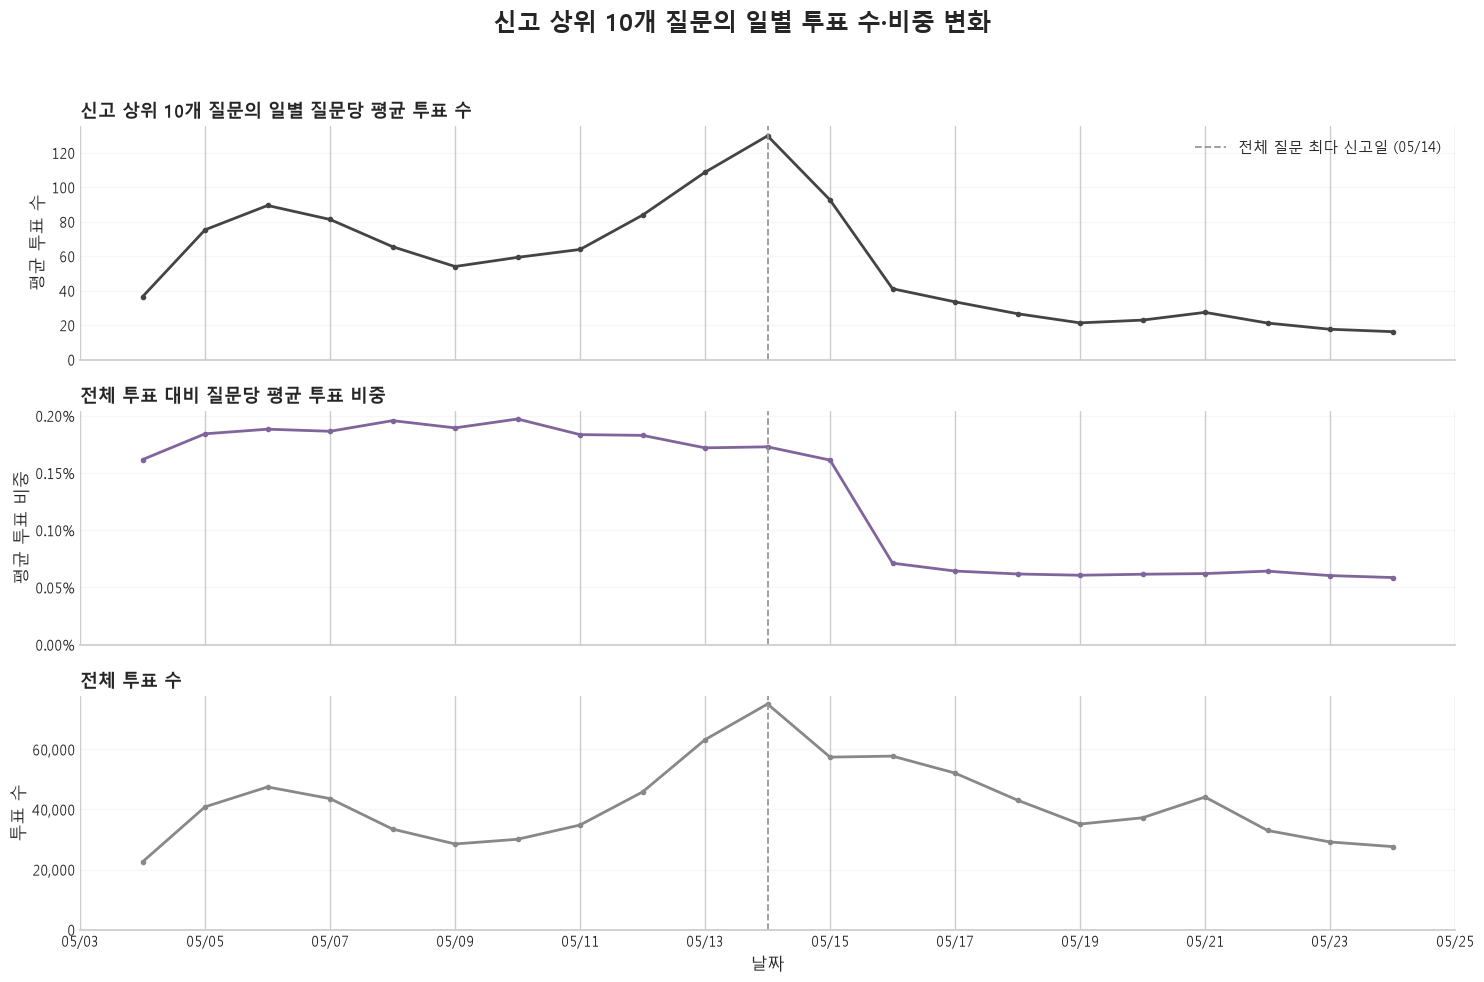

In [28]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter, PercentFormatter

# 그래프 표시 기간: 기준일 전후 10일
df_top10_trend_plot = (
    df_top10_trend_summary.loc[
        df_top10_trend_summary["날짜"].between(
            top10_trend_reference - pd.Timedelta(days=10),
            top10_trend_reference + pd.Timedelta(days=10),
        )
    ]
    .sort_values("날짜")
    .copy()
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharex=True,
)

top10_trend_plot_settings = [
    (
        "질문당 평균 투표 수",
        "신고 상위 10개 질문의 일별 질문당 평균 투표 수",
        "평균 투표 수",
        "#444444",
    ),
    (
        "질문당 평균 투표 비중(%)",
        "전체 투표 대비 질문당 평균 투표 비중",
        "평균 투표 비중",
        "#80649B",
    ),
    (
        "전체 투표 수",
        "전체 투표 수",
        "투표 수",
        "#888888",
    ),
]

for ax, (column, title, ylabel, color) in zip(
    axes, top10_trend_plot_settings
):
    ax.plot(
        df_top10_trend_plot["날짜"],
        df_top10_trend_plot[column],
        color=color,
        marker="o",
        markersize=3,
        linewidth=2,
    )

    ax.axvline(
        top10_trend_reference,
        color="#999999",
        linestyle="--",
        linewidth=1.3,
        label="전체 질문 최다 신고일 (05/14)",
    )

    ax.set_title(
        title,
        loc="left",
        fontsize=13,
        fontweight="bold",
    )
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    ax.margins(y=0.15)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=0)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#CCCCCC")

    if column == "질문당 평균 투표 비중(%)":
        ax.yaxis.set_major_formatter(
            PercentFormatter(xmax=100, decimals=2)
        )
    else:
        ax.yaxis.set_major_formatter(
            StrMethodFormatter("{x:,.0f}")
        )

axes[0].legend(frameon=False, loc="upper right")

axes[2].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
axes[2].set_xlabel("날짜")

fig.suptitle(
    "신고 상위 10개 질문의 일별 투표 수·비중 변화",
    fontsize=17,
    fontweight="bold",
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 5월 14일 전후 신고 상위 10개 질문의 투표·신고 비율


In [29]:
import pandas as pd

top10_rate_mapper = QuestionIdMapper()

top10_rate_reference = pd.Timestamp("2023-05-14")
top10_rate_start = pd.Timestamp("2023-05-04")
top10_rate_end = pd.Timestamp("2023-05-25")  # 미포함

top10_rate_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

if (
    pd.Timestamp(params["start_at"]) > top10_rate_start
    or pd.Timestamp(params["end_at"]) < top10_rate_end
):
    raise ValueError("비교 기간 전체가 조회 범위에 포함되지 않습니다.")

# 1. 남녀 합산 분석 대상 — 공통 유저 제외 조건 유지
df_top10_rate_users = (
    df_user.loc[
        df_user["gender"].isin(["F", "M"])
        & ~df_user["id"].isin(excluded_reporter_ids),
        ["id"],
    ]
    .rename(columns={"id": "user_id"})
)

# 2. 비교 기간의 지정 사유 신고
df_top10_rate_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(top10_rate_reasons),
        ["id", "user_id", "대표 질문 ID", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_top10_rate_reports["시각"] = pd.to_datetime(
    df_top10_rate_reports["created_at"],
    errors="raise",
)

df_top10_rate_reports["대표 질문 ID"] = pd.to_numeric(
    df_top10_rate_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_top10_rate_reports = (
    df_top10_rate_reports.loc[
        df_top10_rate_reports["시각"].ge(top10_rate_start)
        & df_top10_rate_reports["시각"].lt(top10_rate_end)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_top10_rate_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
)

# 3. 비교 기간 전체의 신고 합계 기준 Top 10 선정
df_top10_rate_ranking = (
    df_top10_rate_reports
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .reset_index(name="비교 기간 신고 합계")
    .sort_values(
        ["비교 기간 신고 합계", "대표 질문 ID"],
        ascending=[False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

if df_top10_rate_ranking.empty:
    raise ValueError("비교 기간에 해당하는 신고가 없습니다.")

df_top10_rate_ranking.insert(
    0, "순위", range(1, len(df_top10_rate_ranking) + 1)
)

top10_rate_ids = df_top10_rate_ranking["대표 질문 ID"].tolist()

df_top10_rate_reports = (
    df_top10_rate_reports.loc[
        df_top10_rate_reports["대표 질문 ID"].isin(top10_rate_ids)
    ]
    .copy()
)

# 4. 선정 질문의 투표 기록
df_top10_rate_votes = (
    df_userquestionrecord[
        ["id", "user_id", "question_id", "created_at"]
    ]
    .drop_duplicates("id")
    .copy()
)

df_top10_rate_votes["시각"] = pd.to_datetime(
    df_top10_rate_votes["created_at"],
    errors="raise",
)

df_top10_rate_votes["대표 질문 ID"] = (
    top10_rate_mapper.transform(
        df_top10_rate_votes["question_id"]
    )
)

df_top10_rate_votes = (
    df_top10_rate_votes.loc[
        df_top10_rate_votes["시각"].ge(top10_rate_start)
        & df_top10_rate_votes["시각"].lt(top10_rate_end)
        & df_top10_rate_votes["대표 질문 ID"].isin(top10_rate_ids)
    ]
    .merge(
        df_top10_rate_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
)

# 5. 기준일 전후 구분
def classify_top10_rate_period(series):
    dates = series.dt.normalize()
    periods = pd.Series("기준일", index=series.index)

    periods.loc[dates.lt(top10_rate_reference)] = "이전 10일"
    periods.loc[dates.gt(top10_rate_reference)] = "이후 10일"

    return periods


df_top10_rate_reports["구간"] = classify_top10_rate_period(
    df_top10_rate_reports["시각"]
)

df_top10_rate_votes["구간"] = classify_top10_rate_period(
    df_top10_rate_votes["시각"]
)

# 6. 질문 × 구간별 신고·투표 건수
top10_rate_period_order = ["이전 10일", "기준일", "이후 10일"]

top10_rate_grid = pd.MultiIndex.from_product(
    [top10_rate_ids, top10_rate_period_order],
    names=["대표 질문 ID", "구간"],
)

df_top10_rate_detail = (
    pd.concat(
        [
            df_top10_rate_reports
            .groupby(["대표 질문 ID", "구간"])["id"]
            .nunique()
            .rename("신고 건수"),

            df_top10_rate_votes
            .groupby(["대표 질문 ID", "구간"])["id"]
            .nunique()
            .rename("투표 건수"),
        ],
        axis=1,
    )
    .reindex(top10_rate_grid)
    .fillna(0)
    .astype(int)
    .reset_index()
)

df_top10_rate_detail["투표 대비 신고 비율(%)"] = (
    df_top10_rate_detail["신고 건수"]
    .div(
        df_top10_rate_detail["투표 건수"].where(
            df_top10_rate_detail["투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 7. 질문별 전후 결과를 한 행에 표시
df_top10_rate_comparison = (
    df_top10_rate_ranking
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

for period in ["이전 10일", "이후 10일"]:
    period_result = (
        df_top10_rate_detail.loc[
            df_top10_rate_detail["구간"].eq(period),
            [
                "대표 질문 ID",
                "신고 건수",
                "투표 건수",
                "투표 대비 신고 비율(%)",
            ],
        ]
        .rename(columns={
            "신고 건수": f"{period} 신고 건수",
            "투표 건수": f"{period} 투표 건수",
            "투표 대비 신고 비율(%)": f"{period} 신고 비율(%)",
        })
    )

    df_top10_rate_comparison = (
        df_top10_rate_comparison
        .merge(
            period_result,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
    )

df_top10_rate_comparison["신고 비율 증감(%p)"] = (
    df_top10_rate_comparison["이후 10일 신고 비율(%)"]
    - df_top10_rate_comparison["이전 10일 신고 비율(%)"]
)

print("선정 기준: 2023-05-04 ~ 2023-05-24 신고 합계 Top 10")
print("이전 10일: 2023-05-04 ~ 2023-05-13")
print("이후 10일: 2023-05-15 ~ 2023-05-24")
print("기준일 5월 14일은 전후 비교에서 제외")

display(
    df_top10_rate_comparison[[
        "순위",
        "대표 질문 ID",
        "질문명",
        "비교 기간 신고 합계",
        "이전 10일 신고 건수",
        "이전 10일 투표 건수",
        "이전 10일 신고 비율(%)",
        "이후 10일 신고 건수",
        "이후 10일 투표 건수",
        "이후 10일 신고 비율(%)",
        "신고 비율 증감(%p)",
    ]].round(3)
)

# 8. 선정 질문 전체의 합산 비교
df_top10_rate_total = (
    df_top10_rate_detail
    .groupby("구간")[["신고 건수", "투표 건수"]]
    .sum()
    .reindex(top10_rate_period_order)
)

df_top10_rate_total["투표 대비 신고 비율(%)"] = (
    df_top10_rate_total["신고 건수"]
    .div(
        df_top10_rate_total["투표 건수"].where(
            df_top10_rate_total["투표 건수"].gt(0)
        )
    )
    .mul(100)
)

print("\n[선정 질문 합산]")
display(df_top10_rate_total.reset_index().round(3))

선정 기준: 2023-05-04 ~ 2023-05-24 신고 합계 Top 10
이전 10일: 2023-05-04 ~ 2023-05-13
이후 10일: 2023-05-15 ~ 2023-05-24
기준일 5월 14일은 전후 비교에서 제외


,순위,대표 질문 ID,질문명,비교 기간 신고 합계,이전 10일 신고 건수,이전 10일 투표 건수,이전 10일 신고 비율(%),이후 10일 신고 건수,이후 10일 투표 건수,이후 10일 신고 비율(%),신고 비율 증감(%p)
0,1,111,마스크가 잘 어울리는 사람은?,515,316,607,52.059,135,284,47.535,-4.524
1,2,410,발냄새가 호두과자 냄새일 것 같은 사람은?,481,286,799,35.795,148,307,48.208,12.414
2,3,398,등빨이 가장 좋은 사람은?,400,234,755,30.993,123,318,38.679,7.686
3,4,424,어깨가 가장 넓은 사람은?,288,165,779,21.181,91,317,28.707,7.526
4,5,305,먹방을 가장 잘할 것 같은 사람은?,269,163,873,18.671,74,338,21.893,3.222
5,6,564,설레면 콧구멍이 커지는 친구는?,194,66,173,38.150,92,327,28.135,-10.016
6,7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,193,112,855,13.099,66,346,19.075,5.976
7,8,144,발냄새가 가장 향긋할 것 같은 사람은?,174,104,717,14.505,57,301,18.937,4.432
8,9,479,치킨 중독인 것 같은 사람은?,156,94,793,11.854,46,295,15.593,3.740
9,10,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,154,86,826,10.412,59,371,15.903,5.491



[선정 질문 합산]


,구간,신고 건수,투표 건수,투표 대비 신고 비율(%)
0,이전 10일,1626,7177,22.656
1,기준일,307,1298,23.652
2,이후 10일,891,3204,27.809


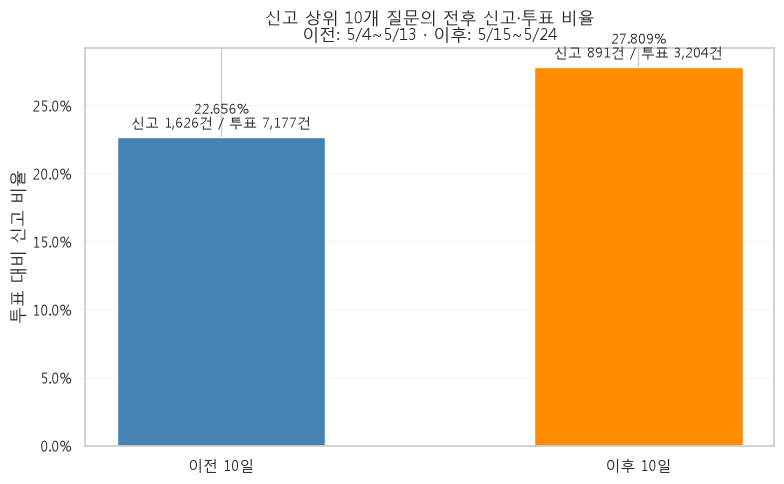

,구간,신고 건수,투표 건수,투표 대비 신고 비율(%)
0,이전 10일,1626,7177,22.656
1,이후 10일,891,3204,27.809


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 앞선 집계 셀에서 계산한 구간별 합계 사용
df_top10_before_after_plot = (
    df_top10_rate_total
    .reindex(["이전 10일", "이후 10일"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    df_top10_before_after_plot["구간"],
    df_top10_before_after_plot["투표 대비 신고 비율(%)"],
    color=["steelblue", "darkorange"],
    width=0.5,
)

for bar, (_, row) in zip(
    bars,
    df_top10_before_after_plot.iterrows(),
):
    if pd.isna(row["투표 대비 신고 비율(%)"]):
        continue

    ax.annotate(
        f"{row['투표 대비 신고 비율(%)']:.3f}%\n"
        f"신고 {int(row['신고 건수']):,}건 / "
        f"투표 {int(row['투표 건수']):,}건",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_title(
    f"신고 상위 {len(top10_rate_ids)}개 질문의 전후 신고·투표 비율\n"
    "이전: 5/4~5/13 · 이후: 5/15~5/24"
)
ax.set_xlabel("")
ax.set_ylabel("투표 대비 신고 비율")
ax.set_ylim(bottom=0)
ax.margins(y=0.3)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

display(df_top10_before_after_plot.round(3))

#### 투표로 제한해서 다시 구해보기

In [58]:
import pandas as pd

school_compare_mapper = QuestionIdMapper()

school_compare_start = pd.Timestamp("2023-05-04")
school_compare_reference = pd.Timestamp("2023-05-14")
school_compare_end = pd.Timestamp("2023-05-25")  # 미포함

school_compare_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

school_compare_period_order = [
    "이전 10일",
    "기준일",
    "이후 10일",
]

if (
    pd.Timestamp(params["start_at"]) > school_compare_start
    or pd.Timestamp(params["end_at"]) < school_compare_end
):
    raise ValueError("比較 기간 전체가 조회 범위에 포함되지 않습니다.")

# 1. 유저 → 학급 → 학교 연결
# 공통 제외 전 유저 정보로 표본 학교를 먼저 확인
df_school_compare_users = (
    df_user[["id", "gender", "group_id"]]
    .rename(columns={"id": "user_id"})
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
)

# 2. 비교 기간의 전체 투표 기록
df_school_compare_votes_raw = (
    df_userquestionrecord[
        ["id", "user_id", "question_id", "created_at"]
    ]
    .drop_duplicates("id")
    .copy()
)

df_school_compare_votes_raw["시각"] = pd.to_datetime(
    df_school_compare_votes_raw["created_at"],
    errors="raise",
)

df_school_compare_votes_raw = (
    df_school_compare_votes_raw.loc[
        df_school_compare_votes_raw["시각"].ge(
            school_compare_start
        )
        & df_school_compare_votes_raw["시각"].lt(
            school_compare_end
        )
    ]
    .merge(
        df_school_compare_users[
            ["user_id", "school_id"]
        ],
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

# 3. 투표자의 소속 학교로 표본 학교 확인
school_compare_school_ids = set(
    df_school_compare_votes_raw["school_id"].dropna()
)

school_compare_unknown_vote_count = (
    df_school_compare_votes_raw.loc[
        df_school_compare_votes_raw["school_id"].isna(),
        "id",
    ].nunique()
)

print(
    "비교 기간 투표자의 소속 학교:",
    f"{len(school_compare_school_ids):,}개",
)
print(
    "학교 연결 불가 투표:",
    f"{school_compare_unknown_vote_count:,}건",
)

if len(school_compare_school_ids) != 10:
    raise ValueError(
        "투표 기록에서 확인된 학교가 10개가 아닙니다. "
        "원본 표본 학교 목록과 비교해 주세요."
    )

# 학교 목록 보관
df_school_compare_school_list = pd.DataFrame({
    "school_id": sorted(school_compare_school_ids)
})

# 4. 같은 10개 학교의 유효 이용자 전체
# 남녀 합산, 공통 제외 조건 유지
school_compare_valid_user_ids = set(
    df_school_compare_users.loc[
        df_school_compare_users["school_id"].isin(
            school_compare_school_ids
        )
        & df_school_compare_users["gender"].isin(["F", "M"])
        & ~df_school_compare_users["user_id"].isin(
            excluded_reporter_ids
        ),
        "user_id",
    ].dropna()
)

# 5. 해당 학교 유효 이용자의 전체 질문 투표
df_school_compare_votes = (
    df_school_compare_votes_raw.loc[
        df_school_compare_votes_raw["user_id"].isin(
            school_compare_valid_user_ids
        )
    ]
    .copy()
)

df_school_compare_votes["대표 질문 ID"] = pd.to_numeric(
    school_compare_mapper.transform(
        df_school_compare_votes["question_id"]
    ),
    errors="raise",
).astype("Int64")

# 의미 불명 등 mapper에서 제외한 질문은 집계하지 않음
df_school_compare_votes = (
    df_school_compare_votes
    .dropna(subset=["대표 질문 ID"])
    .copy()
)

# 6. 같은 학교 이용자의 선정 사유 신고
# 직접 투표·지목 이력이 없어도 해당 학교 소속이면 포함
df_school_compare_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            school_compare_valid_user_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(school_compare_reasons),
        ["id", "user_id", "대표 질문 ID", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_school_compare_reports["시각"] = pd.to_datetime(
    df_school_compare_reports["created_at"],
    errors="raise",
)

df_school_compare_reports["대표 질문 ID"] = pd.to_numeric(
    df_school_compare_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_school_compare_reports = (
    df_school_compare_reports.loc[
        df_school_compare_reports["시각"].ge(
            school_compare_start
        )
        & df_school_compare_reports["시각"].lt(
            school_compare_end
        )
        & df_school_compare_reports["대표 질문 ID"].notna()
    ]
    .copy()
)

# 7. 기준일 전후 구분
def school_compare_classify_period(times):
    dates = times.dt.normalize()
    result = pd.Series("기준일", index=times.index)

    result.loc[dates.lt(school_compare_reference)] = "이전 10일"
    result.loc[dates.gt(school_compare_reference)] = "이후 10일"

    return result


df_school_compare_votes["구간"] = (
    school_compare_classify_period(
        df_school_compare_votes["시각"]
    )
)

df_school_compare_reports["구간"] = (
    school_compare_classify_period(
        df_school_compare_reports["시각"]
    )
)

# 8. 구간별 신고·투표 합계
# Top 10 제한 없이 전체 유효 질문 사용
df_school_compare_total = (
    pd.concat(
        [
            df_school_compare_reports
            .groupby("구간")["id"]
            .nunique()
            .rename("신고 건수"),

            df_school_compare_votes
            .groupby("구간")["id"]
            .nunique()
            .rename("투표 건수"),
        ],
        axis=1,
    )
    .reindex(school_compare_period_order)
    .fillna(0)
    .astype("int64")
)

df_school_compare_total["투표 대비 신고 비율(%)"] = (
    df_school_compare_total["신고 건수"]
    .div(
        df_school_compare_total["투표 건수"].where(
            df_school_compare_total["투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 9. 결과 출력
print("\n분석 대상: 같은 10개 학교의 전체 유효 질문")
print("분석 기간: 2023-05-04 ~ 2023-05-24")
print("이전 10일: 5/4~5/13")
print("기준일: 5/14 — 전후 비교에서 제외")
print("이후 10일: 5/15~5/24")
print("신고 사유: 선정 사유 7개")
print("유저 조건: 남녀 합산·공통 제외 조건 유지")
print(
    "해당 학교의 유효 이용자:",
    f"{len(school_compare_valid_user_ids):,}명",
)
print(
    "기간 내 투표자:",
    f"{df_school_compare_votes['user_id'].nunique():,}명",
)
print(
    "기간 내 신고자:",
    f"{df_school_compare_reports['user_id'].nunique():,}명",
)
print(
    "전체 신고:",
    f"{df_school_compare_reports['id'].nunique():,}건",
)
print(
    "전체 투표:",
    f"{df_school_compare_votes['id'].nunique():,}건",
)

display(df_school_compare_total.reset_index().round(4))

school_compare_before_rate = df_school_compare_total.loc[
    "이전 10일", "투표 대비 신고 비율(%)"
]
school_compare_after_rate = df_school_compare_total.loc[
    "이후 10일", "투표 대비 신고 비율(%)"
]

if (
    pd.notna(school_compare_before_rate)
    and pd.notna(school_compare_after_rate)
):
    print(
        "투표 대비 신고 비율 변화: "
        f"{school_compare_before_rate:.4f}% → "
        f"{school_compare_after_rate:.4f}% "
        f"({school_compare_after_rate - school_compare_before_rate:+.4f}%p)"
    )

비교 기간 투표자의 소속 학교: 10개
학교 연결 불가 투표: 0건

분석 대상: 같은 10개 학교의 전체 유효 질문
분석 기간: 2023-05-04 ~ 2023-05-24
이전 10일: 5/4~5/13
기준일: 5/14 — 전후 비교에서 제외
이후 10일: 5/15~5/24
신고 사유: 선정 사유 7개
유저 조건: 남녀 합산·공통 제외 조건 유지
해당 학교의 유효 이용자: 5,024명
기간 내 투표자: 4,570명
기간 내 신고자: 73명
전체 신고: 168건
전체 투표: 882,321건


,구간,신고 건수,투표 건수,투표 대비 신고 비율(%)
0,이전 10일,74,390491,0.0190
1,기준일,11,75101,0.0146
2,이후 10일,83,416729,0.0199


투표 대비 신고 비율 변화: 0.0190% → 0.0199% (+0.0010%p)


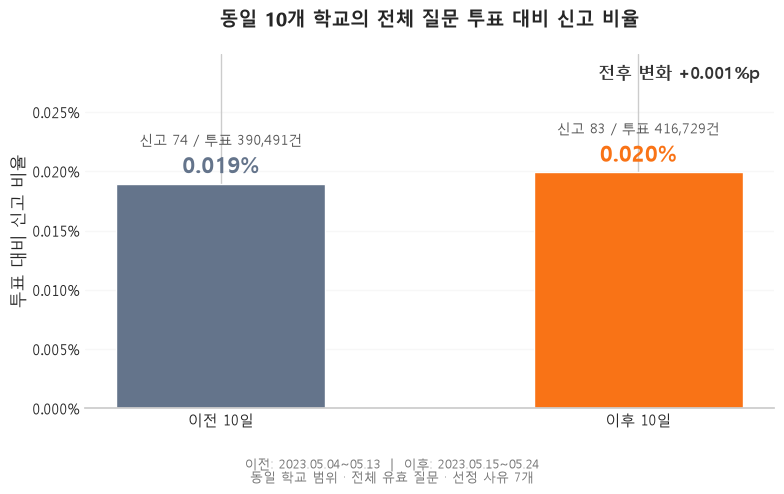

In [59]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

df_school_compare_plot = (
    df_school_compare_total
    .reindex(["이전 10일", "이후 10일"])
    .copy()
)

school_compare_colors = ["#64748B", "#F97316"]

fig, ax = plt.subplots(figsize=(8, 5))

school_compare_bars = ax.bar(
    df_school_compare_plot.index,
    df_school_compare_plot["투표 대비 신고 비율(%)"].fillna(0),
    color=school_compare_colors,
    width=0.5,
)

school_compare_rates = (
    df_school_compare_plot["투표 대비 신고 비율(%)"]
    .dropna()
)

school_compare_ymax = (
    max(float(school_compare_rates.max()) * 1.5, 0.01)
    if not school_compare_rates.empty else 1
)

ax.set_ylim(0, school_compare_ymax)

for bar, (_, row), color in zip(
    school_compare_bars,
    df_school_compare_plot.iterrows(),
    school_compare_colors,
):
    rate = row["투표 대비 신고 비율(%)"]
    center = bar.get_x() + bar.get_width() / 2

    if pd.isna(rate):
        ax.text(
            center,
            school_compare_ymax * 0.05,
            "투표 0건\n비율 계산 불가",
            ha="center",
            color=color,
        )
        continue

    ax.text(
        center,
        rate + school_compare_ymax * 0.03,
        f"{rate:.3f}%",
        ha="center",
        fontsize=16,
        fontweight="bold",
        color=color,
    )

    ax.text(
        center,
        rate + school_compare_ymax * 0.11,
        f"신고 {int(row['신고 건수']):,} / "
        f"투표 {int(row['투표 건수']):,}건",
        ha="center",
        fontsize=10,
        color="#555555",
    )

school_compare_graph_before = df_school_compare_plot.loc[
    "이전 10일", "투표 대비 신고 비율(%)"
]
school_compare_graph_after = df_school_compare_plot.loc[
    "이후 10일", "투표 대비 신고 비율(%)"
]

if (
    pd.notna(school_compare_graph_before)
    and pd.notna(school_compare_graph_after)
):
    ax.text(
        0.98, 0.97,
        "전후 변화 "
        f"{school_compare_graph_after - school_compare_graph_before:+.3f}%p",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=12,
        fontweight="bold",
        color="#333333",
    )

ax.set_title(
    "동일 10개 학교의 전체 질문 투표 대비 신고 비율",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

ax.set_ylabel("투표 대비 신고 비율")
ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100, decimals=3)
)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#CCCCCC")

fig.text(
    0.5, 0.02,
    "이전: 2023.05.04~05.13  |  이후: 2023.05.15~05.24\n"
    "동일 학교 범위 · 전체 유효 질문 · 선정 사유 7개",
    ha="center",
    fontsize=9,
    color="#777777",
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

### 최다 신고일 전후 일별 질문 수 변화


,날짜,신규 질문 수,누적 질문 수
0,2023-05-04,1,460
1,2023-05-05,0,460
2,2023-05-06,0,460
3,2023-05-07,0,460
4,2023-05-08,0,460
5,2023-05-09,0,460
6,2023-05-10,0,460
7,2023-05-11,89,549
8,2023-05-12,0,549
9,2023-05-13,0,549


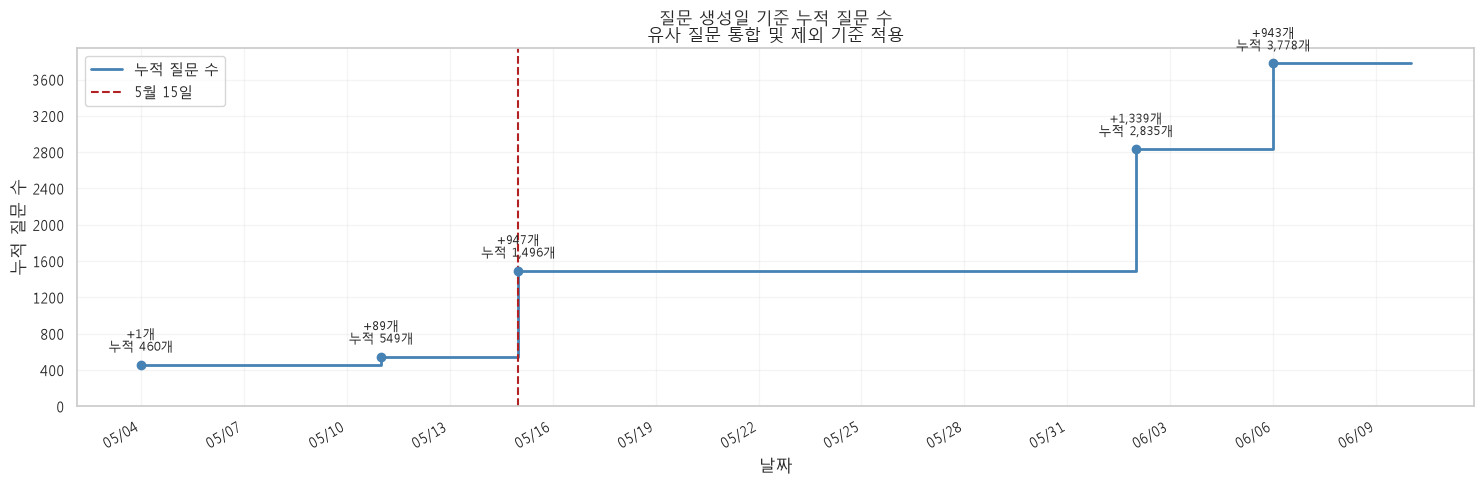

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

mapper = QuestionIdMapper()

# 표시 기간
creation_plot_start = pd.Timestamp("2023-05-04")
creation_plot_end = pd.Timestamp("2023-06-10")

# 1. 전체 원본 질문에 대표 질문 ID 적용
df_question_creation = df_question[[
    "id", "created_at"
]].copy()

df_question_creation["대표 질문 ID"] = mapper.transform(
    df_question_creation["id"]
)

df_question_creation["created_at"] = pd.to_datetime(
    df_question_creation["created_at"]
)

df_question_creation = df_question_creation.dropna(
    subset=["대표 질문 ID", "created_at"]
)

# 2. 대표 질문별 최초 생성일
df_representative_creation = (
    df_question_creation
    .groupby("대표 질문 ID")["created_at"]
    .min()
    .dt.normalize()
    .rename("최초 생성일")
    .reset_index()
)

if df_representative_creation.empty:
    raise ValueError("생성일을 확인할 수 있는 질문이 없습니다.")

# 3. 최초 생성일부터 누적 계산
creation_all_dates = pd.date_range(
    min(
        df_representative_creation["최초 생성일"].min(),
        creation_plot_start,
    ),
    creation_plot_end,
    freq="D",
)

df_cumulative_questions = (
    df_representative_creation
    .groupby("최초 생성일")["대표 질문 ID"]
    .nunique()
    .reindex(creation_all_dates, fill_value=0)
    .rename_axis("날짜")
    .reset_index(name="신규 질문 수")
)

df_cumulative_questions["누적 질문 수"] = (
    df_cumulative_questions["신규 질문 수"].cumsum()
)

# 표시 기간만 선택 — 이전 질문은 누적에 포함된 상태
df_cumulative_questions = (
    df_cumulative_questions.loc[
        df_cumulative_questions["날짜"].between(
            creation_plot_start,
            creation_plot_end,
        )
    ]
    .reset_index(drop=True)
)

display(df_cumulative_questions)

# 4. 그래프
fig, ax = plt.subplots(figsize=(15, 5))

ax.step(
    df_cumulative_questions["날짜"],
    df_cumulative_questions["누적 질문 수"],
    where="post",
    color="steelblue",
    linewidth=2,
    label="누적 질문 수",
)

# 신규 대표 질문이 추가된 날 표시
df_creation_addition_days = df_cumulative_questions.loc[
    df_cumulative_questions["신규 질문 수"].gt(0)
]

ax.scatter(
    df_creation_addition_days["날짜"],
    df_creation_addition_days["누적 질문 수"],
    color="steelblue",
    zorder=3,
)

for _, creation_row in df_creation_addition_days.iterrows():
    ax.annotate(
        f"+{creation_row['신규 질문 수']:,}개\n"
        f"누적 {creation_row['누적 질문 수']:,}개",
        xy=(
            creation_row["날짜"],
            creation_row["누적 질문 수"],
        ),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.axvline(
    pd.Timestamp("2023-05-15"),
    color="firebrick",
    linestyle="--",
    label="5월 15일",
)

ax.set_title(
    "질문 생성일 기준 누적 질문 수\n"
    "유사 질문 통합 및 제외 기준 적용"
)
ax.set_xlabel("날짜")
ax.set_ylabel("누적 질문 수")
ax.set_ylim(bottom=0)
ax.margins(y=0.2)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

ax.grid(alpha=0.2)
ax.legend()
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

### 질문 추가 전후 기존·신규 질문의 신고 추이


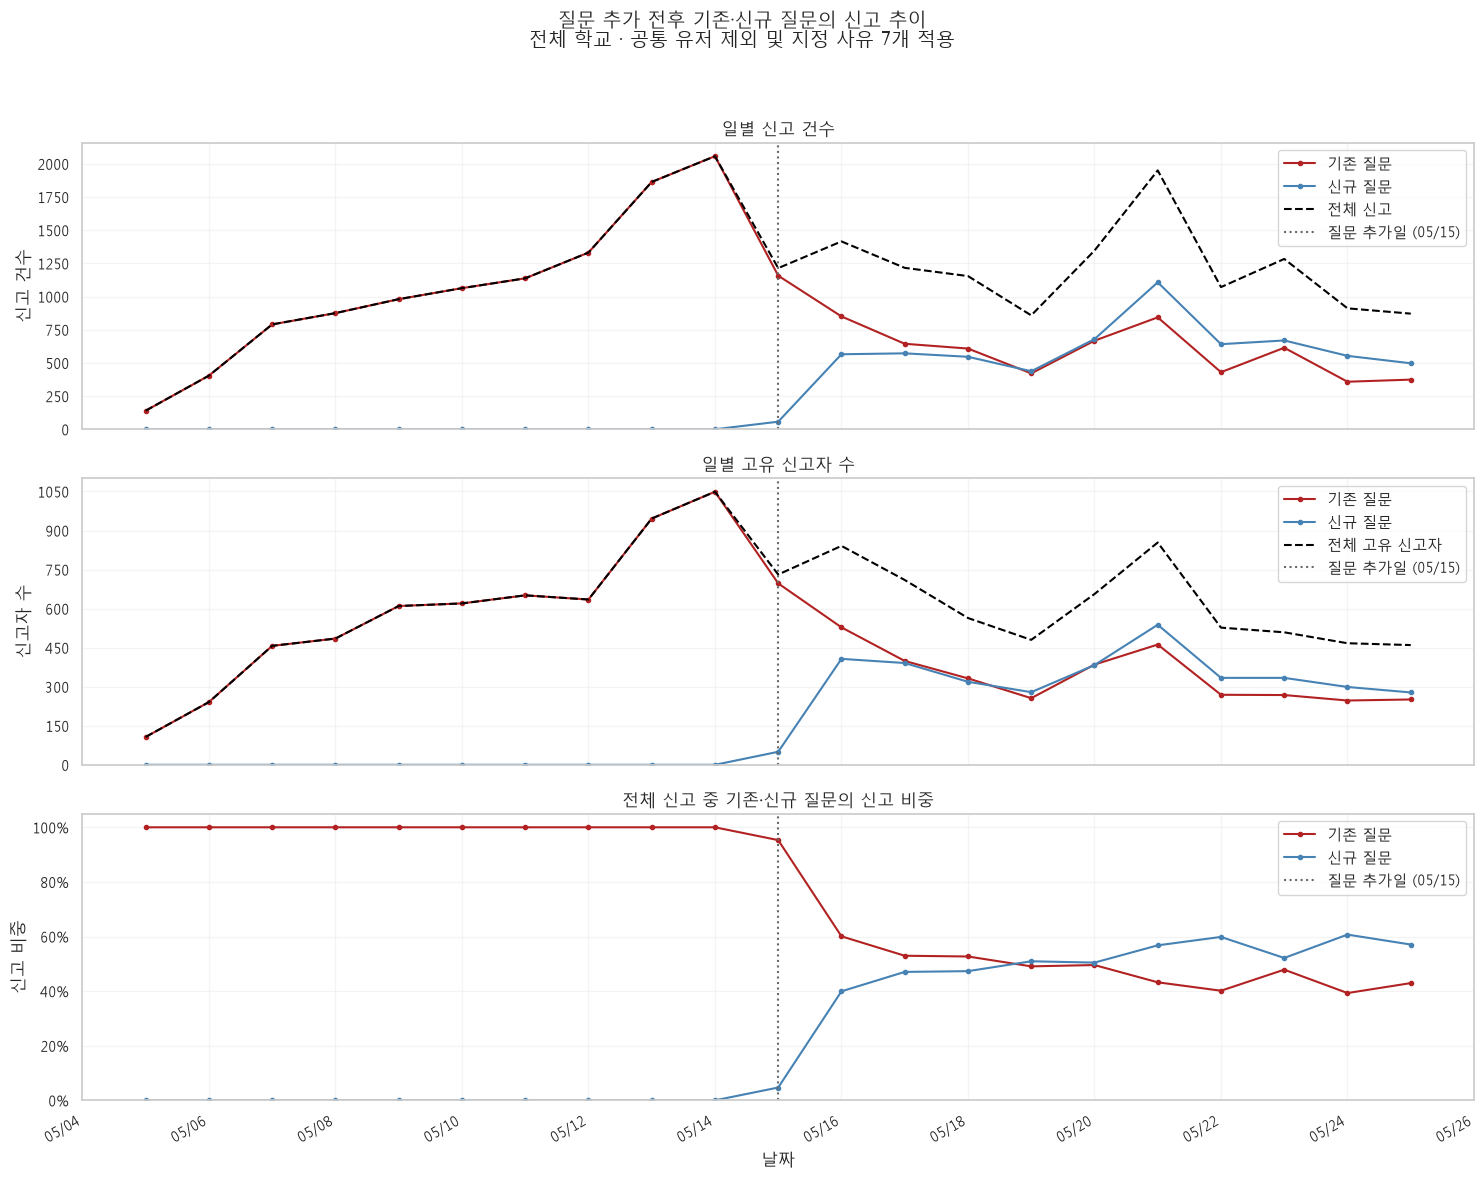

일별 신고 현황


,날짜,기존 질문 신고 건수,기존 질문 신고자 수,신규 질문 신고 건수,신규 질문 신고자 수,분류 확인 불가 신고 건수,분류 확인 불가 신고자 수,전체 신고 건수,전체 신고자 수,기존 질문 신고 비중(%),신규 질문 신고 비중(%)
0,2023-05-05,140,107,0,0,0,0,140,107,100.00,0.00
1,2023-05-06,404,241,0,0,0,0,404,241,100.00,0.00
2,2023-05-07,790,457,0,0,0,0,790,457,100.00,0.00
3,2023-05-08,875,485,0,0,0,0,875,485,100.00,0.00
4,2023-05-09,980,610,0,0,0,0,980,610,100.00,0.00
5,2023-05-10,1063,620,0,0,0,0,1063,620,100.00,0.00
6,2023-05-11,1137,651,0,0,0,0,1137,651,100.00,0.00
7,2023-05-12,1331,635,0,0,0,0,1331,635,100.00,0.00
8,2023-05-13,1863,946,0,0,0,0,1863,946,100.00,0.00
9,2023-05-14,2057,1049,0,0,0,0,2057,1049,100.00,0.00


추가 전후 요약


,비교 구간,질문 구분,신고 건수,고유 신고자 수,신고된 질문 수
0,추가 전,기존 질문,10640,4161,548
1,추가 전,신규 질문,0,0,0
2,추가 전,분류 확인 불가,0,0,0
3,추가 당일,기존 질문,1157,697,390
4,추가 당일,신규 질문,57,50,52
5,추가 당일,분류 확인 불가,0,0,0
6,추가 후,기존 질문,5809,2728,545
7,추가 후,신규 질문,6266,2794,934
8,추가 후,분류 확인 불가,0,0,0


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator, PercentFormatter

question_change_mapper = QuestionIdMapper()

question_change_date = pd.Timestamp("2023-05-15")

# 기본 비교 기간: 추가일 전후 10일
# 필요하면 아래 날짜를 변경하시면 됩니다.
question_change_start = pd.Timestamp("2023-05-05")
question_change_end = pd.Timestamp("2023-05-25")  # 포함

question_change_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 조회 범위를 벗어난 날짜를 0건으로 처리하지 않도록 확인
question_change_end_exclusive = (
    question_change_end + pd.Timedelta(days=1)
)

if (
    pd.Timestamp(params["start_at"]) > question_change_start
    or pd.Timestamp(params["end_at"]) < question_change_end_exclusive
):
    raise ValueError(
        "비교 기간 전체가 원본 조회 범위에 포함되는지 확인해 주세요."
    )


# 1. 대표 질문 묶음의 최초 생성일
df_question_change_creation = df_question[
    ["id", "created_at"]
].copy()

df_question_change_creation["대표 질문 ID"] = (
    question_change_mapper.transform(
        df_question_change_creation["id"]
    )
)

df_question_change_creation["질문 생성 시각"] = pd.to_datetime(
    df_question_change_creation["created_at"],
    errors="raise",
)

df_question_change_creation = (
    df_question_change_creation
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID", as_index=False)
    .agg(
        최초_생성_시각=("질문 생성 시각", "min"),
        생성일_결측_있음=(
            "질문 생성 시각", lambda s: s.isna().any()
        ),
    )
    .rename(columns={"최초_생성_시각": "최초 생성 시각"})
)

df_question_change_creation["질문 구분"] = "분류 확인 불가"

question_change_known_creation = (
    df_question_change_creation["최초 생성 시각"].notna()
    & ~df_question_change_creation["생성일_결측_있음"]
)

df_question_change_creation.loc[
    question_change_known_creation
    & df_question_change_creation["최초 생성 시각"].lt(
        question_change_date
    ),
    "질문 구분",
] = "기존 질문"

df_question_change_creation.loc[
    question_change_known_creation
    & df_question_change_creation["최초 생성 시각"].ge(
        question_change_date
    ),
    "질문 구분",
] = "신규 질문"


# 2. 전체 학교 범위의 지정 사유 신고
df_question_change_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(question_change_reasons),
        ["id", "user_id", "대표 질문 ID", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_question_change_reports["신고 시각"] = pd.to_datetime(
    df_question_change_reports["created_at"],
    errors="raise",
)

df_question_change_reports["날짜"] = (
    df_question_change_reports["신고 시각"].dt.normalize()
)

df_question_change_reports = (
    df_question_change_reports.loc[
        df_question_change_reports["신고 시각"].ge(
            question_change_start
        )
        & df_question_change_reports["신고 시각"].lt(
            question_change_end_exclusive
        )
    ]
    .merge(
        df_question_change_creation[[
            "대표 질문 ID",
            "최초 생성 시각",
            "질문 구분",
        ]],
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
)

df_question_change_reports["질문 구분"] = (
    df_question_change_reports["질문 구분"]
    .fillna("분류 확인 불가")
)

# 生成時刻より前の 신고가 있으면 연결 데이터 확인
question_change_invalid_time = (
    df_question_change_reports["최초 생성 시각"].notna()
    & df_question_change_reports["신고 시각"].lt(
        df_question_change_reports["최초 생성 시각"]
    )
)

if question_change_invalid_time.any():
    raise ValueError(
        "질문 최초 생성 시각보다 이른 신고가 있습니다. "
        "날짜·시간대 또는 질문 매핑을 확인해 주세요."
    )


# 3. 날짜별 신고 건수
question_change_dates = pd.date_range(
    question_change_start,
    question_change_end,
    freq="D",
)

question_change_types = [
    "기존 질문",
    "신규 질문",
    "분류 확인 불가",
]

df_question_change_daily_counts = (
    df_question_change_reports
    .groupby(["날짜", "질문 구분"])["id"]
    .nunique()
    .unstack("질문 구분", fill_value=0)
    .reindex(
        index=question_change_dates,
        columns=question_change_types,
        fill_value=0,
    )
    .rename_axis(index="날짜", columns=None)
)

# 날짜별 유형별 고유 신고자 수
df_question_change_daily_users = (
    df_question_change_reports
    .groupby(["날짜", "질문 구분"])["user_id"]
    .nunique()
    .unstack("질문 구분", fill_value=0)
    .reindex(
        index=question_change_dates,
        columns=question_change_types,
        fill_value=0,
    )
    .rename_axis(index="날짜", columns=None)
)

# 날짜별 전체 고유 신고자 수
# 기존·신규 모두 신고한 유저는 한 번만 계산
question_change_total_users = (
    df_question_change_reports
    .groupby("날짜")["user_id"]
    .nunique()
    .reindex(question_change_dates, fill_value=0)
)


# 4. 일별 집계표
df_question_change_daily = pd.DataFrame(
    index=question_change_dates
)

for question_type in question_change_types:
    df_question_change_daily[f"{question_type} 신고 건수"] = (
        df_question_change_daily_counts[question_type]
    )
    df_question_change_daily[f"{question_type} 신고자 수"] = (
        df_question_change_daily_users[question_type]
    )

df_question_change_daily["전체 신고 건수"] = (
    df_question_change_daily_counts.sum(axis=1)
)

df_question_change_daily["전체 신고자 수"] = (
    question_change_total_users
)

for question_type in ["기존 질문", "신규 질문"]:
    df_question_change_daily[f"{question_type} 신고 비중(%)"] = (
        df_question_change_daily[f"{question_type} 신고 건수"]
        .div(
            df_question_change_daily["전체 신고 건수"].where(
                df_question_change_daily["전체 신고 건수"].gt(0)
            )
        )
        .mul(100)
    )

df_question_change_daily = (
    df_question_change_daily
    .rename_axis("날짜")
    .reset_index()
)


# 5. 추가 전후 요약 — 기간 전체에서 고유 신고자 중복 제거
df_question_change_reports["비교 구간"] = "추가 당일"

df_question_change_reports.loc[
    df_question_change_reports["날짜"].lt(question_change_date),
    "비교 구간",
] = "추가 전"

df_question_change_reports.loc[
    df_question_change_reports["날짜"].gt(question_change_date),
    "비교 구간",
] = "추가 후"

df_question_change_period_summary = (
    df_question_change_reports
    .groupby(["비교 구간", "질문 구분"])
    .agg(
        신고_건수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
        신고된_질문_수=("대표 질문 ID", "nunique"),
    )
    .reindex(
        pd.MultiIndex.from_product(
            [
                ["추가 전", "추가 당일", "추가 후"],
                question_change_types,
            ],
            names=["비교 구간", "질문 구분"],
        ),
        fill_value=0,
    )
    .reset_index()
    .rename(columns={
        "신고_건수": "신고 건수",
        "고유_신고자_수": "고유 신고자 수",
        "신고된_질문_수": "신고된 질문 수",
    })
)


# 6. 그래프
fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 12),
    sharex=True,
)

question_change_colors = {
    "기존 질문": "firebrick",
    "신규 질문": "steelblue",
    "분류 확인 불가": "gray",
}

for question_type in question_change_types:
    # 기록이 없는 확인 불가 유형은 그래프에서 생략
    if (
        question_type == "분류 확인 불가"
        and df_question_change_daily[
            f"{question_type} 신고 건수"
        ].sum() == 0
    ):
        continue

    axes[0].plot(
        df_question_change_daily["날짜"],
        df_question_change_daily[f"{question_type} 신고 건수"],
        marker="o",
        markersize=3,
        color=question_change_colors[question_type],
        label=question_type,
    )

    axes[1].plot(
        df_question_change_daily["날짜"],
        df_question_change_daily[f"{question_type} 신고자 수"],
        marker="o",
        markersize=3,
        color=question_change_colors[question_type],
        label=question_type,
    )

axes[0].plot(
    df_question_change_daily["날짜"],
    df_question_change_daily["전체 신고 건수"],
    color="black",
    linestyle="--",
    label="전체 신고",
)

axes[0].set_title("일별 신고 건수")
axes[0].set_ylabel("신고 건수")

axes[1].plot(
    df_question_change_daily["날짜"],
    df_question_change_daily["전체 신고자 수"],
    color="black",
    linestyle="--",
    label="전체 고유 신고자",
)

axes[1].set_title("일별 고유 신고자 수")
axes[1].set_ylabel("신고자 수")

for question_type in ["기존 질문", "신규 질문"]:
    axes[2].plot(
        df_question_change_daily["날짜"],
        df_question_change_daily[f"{question_type} 신고 비중(%)"],
        marker="o",
        markersize=3,
        color=question_change_colors[question_type],
        label=question_type,
    )

axes[2].set_title("전체 신고 중 기존·신규 질문의 신고 비중")
axes[2].set_ylabel("신고 비중")
axes[2].set_xlabel("날짜")
axes[2].set_ylim(0, 105)
axes[2].yaxis.set_major_formatter(PercentFormatter(xmax=100))

for ax in axes:
    ax.axvline(
        question_change_date,
        color="dimgray",
        linestyle=":",
        linewidth=1.5,
        label="질문 추가일 (05/15)",
    )
    ax.grid(alpha=0.2)
    ax.legend(loc="best")

for ax in axes[:2]:
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

axes[2].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

fig.suptitle(
    "질문 추가 전후 기존·신규 질문의 신고 추이\n"
    "전체 학교 · 공통 유저 제외 및 지정 사유 7개 적용",
    fontsize=14,
)

fig.autofmt_xdate()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("일별 신고 현황")
display(df_question_change_daily.round(2))

print("추가 전후 요약")
display(df_question_change_period_summary)

## 신고자의 서비스 이용 특성


### 5/14~6/13 투표자의 재투표율 및 재투표일 수


In [33]:
import numpy as np
import pandas as pd

# 기준 투표자 선정 기간
trim_return_start = pd.Timestamp("2023-05-14")
trim_return_end = pd.Timestamp("2023-06-14")  # 6월 13일까지 포함
trim_return_ratio = 0.10  # 양쪽 각각 10% 절사

# 1. 전체 투표 기록
# 이후 재투표 확인을 위해 6월 13일 이후 기록도 유지
df_trim_return_votes = (
    df_userquestionrecord[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_trim_return_votes["투표 시각"] = pd.to_datetime(
    df_trim_return_votes["created_at"],
    errors="raise",
)

df_trim_return_votes["투표일"] = (
    df_trim_return_votes["투표 시각"].dt.normalize()
)

# 2. 5/14~6/13에 투표한 유저별 기간 내 첫 투표일
df_trim_return_cohort = (
    df_trim_return_votes.loc[
        df_trim_return_votes["투표 시각"].ge(trim_return_start)
        & df_trim_return_votes["투표 시각"].lt(trim_return_end)
    ]
    .groupby("user_id")["투표일"]
    .min()
    .reset_index(name="기준일")
)

if df_trim_return_cohort.empty:
    raise ValueError("선정 기간에 투표한 유저가 없습니다.")

# 모든 유저의 이후 30일이 조회 범위에 포함되는지 확인
if (
    df_trim_return_cohort["기준일"]
    + pd.Timedelta(days=31)
).gt(pd.Timestamp(params["end_at"])).any():
    raise ValueError("일부 유저의 기준일 이후 30일을 조회할 수 없습니다.")

# 3. 전체 조회 기간의 신고 여부로 집단 고정
# 원본 신고 사용: 신고 사유·공통 유저 제외 조건 미적용
df_trim_return_reports = (
    df_questionreport[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_trim_return_reports["신고 시각"] = pd.to_datetime(
    df_trim_return_reports["created_at"],
    errors="raise",
)

trim_return_reporter_ids = set(
    df_trim_return_reports.loc[
        df_trim_return_reports["신고 시각"].ge(
            pd.Timestamp(params["start_at"])
        )
        & df_trim_return_reports["신고 시각"].lt(
            pd.Timestamp(params["end_at"])
        ),
        "user_id",
    ]
)

df_trim_return_cohort["집단"] = (
    df_trim_return_cohort["user_id"]
    .isin(trim_return_reporter_ids)
    .map({True: "신고자", False: "비신고자"})
)

# 4. 개인별 기준일 이후 투표 연결
df_trim_return_detail = (
    df_trim_return_cohort[["user_id", "기준일"]]
    .merge(
        df_trim_return_votes[["user_id", "투표일"]]
        .drop_duplicates(),
        on="user_id",
        how="inner",
        validate="one_to_many",
    )
)

df_trim_return_detail["경과일"] = (
    df_trim_return_detail["투표일"]
    - df_trim_return_detail["기준일"]
).dt.days

# 같은 날 제외, 이후 30일만 포함
df_trim_return_detail = (
    df_trim_return_detail.loc[
        df_trim_return_detail["경과일"].between(1, 30)
    ]
    .copy()
)

# 5. 개인별 1일·7일·30일 내 고유 재투표일 수
df_trim_return_users = df_trim_return_cohort.copy()

for days in [1, 7, 30]:
    day_counts = (
        df_trim_return_detail.loc[
            df_trim_return_detail["경과일"].between(1, days)
        ]
        .groupby("user_id")["투표일"]
        .nunique()
    )

    df_trim_return_users[f"{days}일 내 재투표일 수"] = (
        df_trim_return_users["user_id"]
        .map(day_counts)
        .fillna(0)
        .astype(int)
    )

# 6. 집단별 재투표율 및 양측 10% 절사평균
trim_return_rows = []

for group in ["신고자", "비신고자"]:
    group_users = df_trim_return_users.loc[
        df_trim_return_users["집단"].eq(group)
    ]

    for days in [1, 7, 30]:
        counts = group_users[f"{days}일 내 재투표일 수"]

        # 절사평균에서는 0일 제외
        positive_values = np.sort(
            counts.loc[counts.gt(0)].to_numpy()
        )

        trim_count = int(len(positive_values) * trim_return_ratio)

        trimmed_values = (
            positive_values[trim_count:-trim_count]
            if trim_count > 0
            else positive_values
        )

        trim_return_rows.append({
            "집단": group,
            "구간": f"{days}일 내",
            "전체 대상 유저 수": len(group_users),
            "재투표 유저 수": len(positive_values),
            "재투표율(%)": (
                counts.gt(0).mean() * 100
                if len(group_users) else float("nan")
            ),
            "재투표자 평균 재투표일 수": (
                positive_values.mean()
                if len(positive_values) else float("nan")
            ),
            "각 꼬리 절사 인원": trim_count,
            "절사평균 재투표일 수": (
                trimmed_values.mean()
                if len(trimmed_values) else float("nan")
            ),
        })

df_trim_return_summary = pd.DataFrame(trim_return_rows)

print("기준 투표자 선정: 2023-05-14 ~ 2023-06-13")
print("개인별 기준일: 선정 기간 내 첫 투표일")
print("후속 투표 확인: 각 기준일 다음 날부터 30일간")
print("최대 후속 관측일: 2023-07-13")

display(df_trim_return_summary.round(3))


기준 투표자 선정: 2023-05-14 ~ 2023-06-13
개인별 기준일: 선정 기간 내 첫 투표일
후속 투표 확인: 각 기준일 다음 날부터 30일간
최대 후속 관측일: 2023-07-13


,집단,구간,전체 대상 유저 수,재투표 유저 수,재투표율(%),재투표자 평균 재투표일 수,각 꼬리 절사 인원,절사평균 재투표일 수
0,신고자,1일 내,150,126,84.000,1.000,12,1.000
1,신고자,7일 내,150,139,92.667,4.942,13,5.124
2,신고자,30일 내,150,139,92.667,9.266,13,8.823
3,비신고자,1일 내,4032,2838,70.387,1.000,283,1.000
4,비신고자,7일 내,4032,3459,85.789,4.460,345,4.575
5,비신고자,30일 내,4032,3612,89.583,7.519,361,6.900


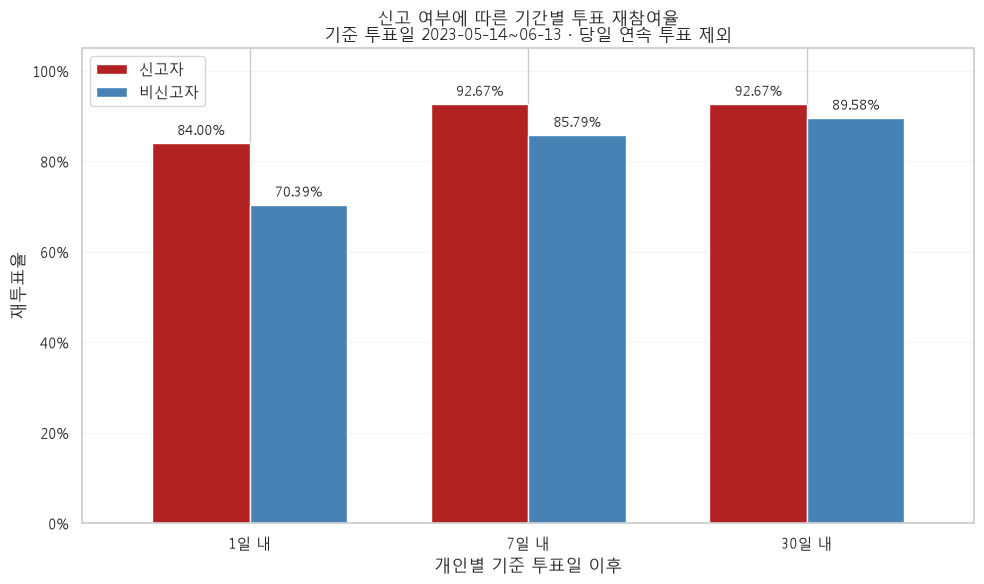

In [34]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 기존 집계 결과 사용
df_revote_rate_plot = (
    df_trim_return_summary
    .pivot(
        index="구간",
        columns="집단",
        values="재투표율(%)",
    )
    .reindex(
        index=["1일 내", "7일 내", "30일 내"],
        columns=["신고자", "비신고자"],
    )
)

ax = df_revote_rate_plot.plot.bar(
    figsize=(10, 6),
    color=["firebrick", "steelblue"],
    width=0.7,
    rot=0,
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4,
        fontsize=10,
    )

ax.set_title(
    "신고 여부에 따른 기간별 투표 재참여율\n"
    "기준 투표일 2023-05-14~06-13 · 당일 연속 투표 제외"
)
ax.set_xlabel("개인별 기준 투표일 이후")
ax.set_ylabel("재투표율")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title="")

plt.tight_layout()
plt.show()

### 5/14~6/13 신고자·비신고자의 구매 기록


In [35]:
import pandas as pd

purchase_period_start = pd.Timestamp("2023-05-14")
purchase_period_end = pd.Timestamp("2023-06-14")  # 미포함

# 1. 기간 시작 전에 가입한 일반 유저
df_period_purchase_users = (
    df_user[["id", "created_at"]]
    .rename(columns={
        "id": "user_id",
        "created_at": "가입 시각",
    })
    .drop_duplicates("user_id")
    .copy()
)

df_period_purchase_users["가입 시각"] = pd.to_datetime(
    df_period_purchase_users["가입 시각"],
    errors="raise",
)

df_period_purchase_users = (
    df_period_purchase_users.loc[
        df_period_purchase_users["가입 시각"].lt(
            purchase_period_start
        )
    ]
    .copy()
)

# 2. 같은 기간의 질문 신고
# 원본 신고 전체 사용: 사유·공통 유저 제외 조건 미적용
df_period_purchase_reports = (
    df_questionreport[["id", "user_id", "created_at"]]
    .drop_duplicates("id")
    .copy()
)

df_period_purchase_reports["신고 시각"] = pd.to_datetime(
    df_period_purchase_reports["created_at"],
    errors="raise",
)

period_purchase_reporter_ids = set(
    df_period_purchase_reports.loc[
        df_period_purchase_reports["신고 시각"].ge(
            purchase_period_start
        )
        & df_period_purchase_reports["신고 시각"].lt(
            purchase_period_end
        ),
        "user_id",
    ].dropna()
)

df_period_purchase_users["집단"] = (
    df_period_purchase_users["user_id"]
    .isin(period_purchase_reporter_ids)
    .map({
        True: "기간 내 신고자",
        False: "기간 내 비신고자",
    })
)

# 3. 같은 기간의 구매 기록
df_period_purchase_records = (
    df_paymenthistory[["id", "user_id", "created_at"]]
    .drop_duplicates("id")
    .copy()
)

df_period_purchase_records["구매 시각"] = pd.to_datetime(
    df_period_purchase_records["created_at"],
    errors="raise",
)

df_period_purchase_records = (
    df_period_purchase_records.loc[
        df_period_purchase_records["구매 시각"].ge(
            purchase_period_start
        )
        & df_period_purchase_records["구매 시각"].lt(
            purchase_period_end
        )
    ]
    .copy()
)

period_purchase_counts = (
    df_period_purchase_records
    .groupby("user_id")["id"]
    .nunique()
    .rename("기간 내 구매 횟수")
    .reset_index()
)

# 구매하지 않은 유저도 유지
df_period_purchase_result = (
    df_period_purchase_users
    .merge(
        period_purchase_counts,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

df_period_purchase_result["기간 내 구매 횟수"] = (
    df_period_purchase_result["기간 내 구매 횟수"]
    .fillna(0)
    .astype(int)
)

# 4. 신고자·비신고자 비교
df_period_purchase_summary = (
    df_period_purchase_result
    .groupby("집단")
    .agg(
        유저_수=("user_id", "nunique"),
        구매_유저_수=(
            "기간 내 구매 횟수", lambda s: s.gt(0).sum()
        ),
        구매_기록_수=("기간 내 구매 횟수", "sum"),
        유저당_평균_구매_횟수=("기간 내 구매 횟수", "mean"),
        구매자당_평균_구매_횟수=(
            "기간 내 구매 횟수",
            lambda s: s.loc[s.gt(0)].mean(),
        ),
    )
    .reindex(["기간 내 신고자", "기간 내 비신고자"])
    .rename(columns={
        "유저_수": "유저 수",
        "구매_유저_수": "구매 유저 수",
        "구매_기록_수": "구매 기록 수",
        "유저당_평균_구매_횟수": "전체 유저당 평균 구매 횟수",
        "구매자당_평균_구매_횟수": "구매자당 평균 구매 횟수",
    })
)

df_period_purchase_summary["구매 기록 보유율(%)"] = (
    df_period_purchase_summary["구매 유저 수"]
    .div(
        df_period_purchase_summary["유저 수"].where(
            df_period_purchase_summary["유저 수"].gt(0)
        )
    )
    .mul(100)
)

print("분석 기간: 2023-05-14 ~ 2023-06-13")
print("대상: 5월 14일 이전 가입한 일반 유저")

display(
    df_period_purchase_summary.reset_index()[[
        "집단",
        "유저 수",
        "구매 유저 수",
        "구매 기록 보유율(%)",
        "구매 기록 수",
        "전체 유저당 평균 구매 횟수",
        "구매자당 평균 구매 횟수",
    ]].round(3)
)

분석 기간: 2023-05-14 ~ 2023-06-13
대상: 5월 14일 이전 가입한 일반 유저


,집단,유저 수,구매 유저 수,구매 기록 보유율(%),구매 기록 수,전체 유저당 평균 구매 횟수,구매자당 평균 구매 횟수
0,기간 내 신고자,6641,1015,15.284,1803,0.271,1.776
1,기간 내 비신고자,358020,24189,6.756,36789,0.103,1.521


# 부록


### 전처리한 질문 CSV 파일로 내보내기


In [36]:
from pathlib import Path

save_path = Path.cwd() / "대표질문_통합목록.csv"

if save_path.exists():
    print(f"파일이 이미 있어 실행을 건너뜁니다: {save_path.resolve()}")

else:
    mapper = QuestionIdMapper()

    df_question_export = df_question[
        ["id", "question_text"]
    ].copy()

    df_question_export["대표 질문 ID"] = mapper.transform(
        df_question_export["id"]
    )

    # 제외 대상 질문 제거
    df_question_export = df_question_export.dropna(
        subset=["대표 질문 ID"]
    )

    # 같은 묶음에 포함된 원본 ID 보관
    df_question_export = (
        df_question_export
        .groupby("대표 질문 ID")
        .agg(
            원본_질문_ID=("id", lambda s: ", ".join(
                map(str, sorted(s))
            )),
            통합_질문_수=("id", "size"),
        )
        .reset_index()
        .merge(
            df_question[["id", "question_text"]].rename(columns={
                "id": "대표 질문 ID",
                "question_text": "대표 질문명",
            }),
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
        .rename(columns={
            "원본_질문_ID": "원본 질문 ID 목록",
            "통합_질문_수": "통합된 원본 질문 수",
        })
        .sort_values("대표 질문 ID")
        .reset_index(drop=True)
    )

    df_question_export["대표 질문 ID"] = (
        df_question_export["대표 질문 ID"].astype("int64")
    )

    df_question_export = df_question_export[[
        "대표 질문 ID",
        "대표 질문명",
        "원본 질문 ID 목록",
        "통합된 원본 질문 수",
    ]]

    df_question_export.to_csv(
        save_path,
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )

    print(f"통합 후 질문 수: {len(df_question_export):,}개")
    print(f"저장 위치: {save_path.resolve()}")

    display(df_question_export.head(10))

파일이 이미 있어 실행을 건너뜁니다: C:\Users\USER\Desktop\final_prj\codeit-sns-moderation\대표질문_통합목록.csv


### 질문 신고자의 차단·숨김 실행 현황


In [37]:
import json
import pandas as pd

user_base = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0)
].copy()

if user_base["id"].isna().any() or user_base["id"].duplicated().any():
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hidden_users(value):
    if isinstance(value, str):
        value = json.loads(value)
    elif isinstance(value, list):
        pass
    elif pd.isna(value):
        return pd.NA
    else:
        raise ValueError("숨김 목록 형식을 확인해 주세요.")

    if value is None:
        return pd.NA

    if not isinstance(value, list):
        raise ValueError("숨김 목록이 리스트 형식이 아닙니다.")

    return len(value) > 0


# 차단한 사람: 차단 기록의 user_id
blocker_ids = set(df_blockrecord["user_id"].dropna())

df_user_action_flags = user_base[["id"]].copy()

df_user_action_flags["차단 실행"] = (
    df_user_action_flags["id"].isin(blocker_ids)
)

# 숨김한 사람: 본인의 숨김 목록에 대상이 한 명 이상 있음
df_user_action_flags["숨김 실행"] = (
    user_base["hide_user_id_list"]
    .apply(has_hidden_users)
    .astype("boolean")
)

total_users = len(df_user_action_flags)

df_user_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(
            df_user_action_flags[column].fillna(False).sum()
        ),
        "전체 일반 유저 수": total_users,
        "전체 대비 비율(%)": (
            df_user_action_flags[column].fillna(False).sum()
            / total_users * 100
            if total_users else float("nan")
        ),
    }
    for label, column in [
        ("차단한 유저", "차단 실행"),
        ("숨김한 유저", "숨김 실행"),
    ]
])

print(
    "숨김 목록 확인 불가:",
    f"{df_user_action_flags['숨김 실행'].isna().sum():,}명",
)

df_user_action_ratio.round(2)

숨김 목록 확인 불가: 0명


,구분,고유 유저 수,전체 일반 유저 수,전체 대비 비율(%)
0,차단한 유저,12551,677081,1.85
1,숨김한 유저,78733,677081,11.63


In [38]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_reporter_actions = (
    df_questionreport_clean.loc[~positive_mask, ["user_id"]]
    .dropna(subset=["user_id"])
    .drop_duplicates()
    .merge(
        df_user_action_flags.rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

# 일반 유저 정보에 연결되지 않는 신고자를 자동 제외하지 않음
unmatched = df_reporter_actions["_merge"].ne("both")

if unmatched.any():
    raise ValueError(
        f"일반 유저 정보에 연결되지 않는 신고자가 "
        f"{unmatched.sum():,}명 있습니다. 분석 대상 범위를 확인해 주세요."
    )

block = df_reporter_actions["차단 실행"].astype("boolean")
hide = df_reporter_actions["숨김 실행"].astype("boolean")

total_reporters = len(df_reporter_actions)

conditions = [
    ("차단한 질문 신고자", block),
    ("숨김한 질문 신고자", hide),
    ("차단·숨김 모두 한 질문 신고자", block & hide),
    ("차단 또는 숨김한 질문 신고자", block | hide),
]

df_reporter_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(mask.fillna(False).sum()),
        "전체 질문 신고자 수": total_reporters,
        "확인 불가 유저 수": int(mask.isna().sum()),
        "질문 신고자 대비 비율(%)": (
            mask.fillna(False).sum() / total_reporters * 100
            if total_reporters else float("nan")
        ),
    }
    for label, mask in conditions
])

df_reporter_action_ratio.round(2)

,구분,고유 유저 수,전체 질문 신고자 수,확인 불가 유저 수,질문 신고자 대비 비율(%)
0,차단한 질문 신고자,1087,20544,0,5.29
1,숨김한 질문 신고자,4529,20544,0,22.05
2,차단·숨김 모두 한 질문 신고자,488,20544,0,2.38
3,차단 또는 숨김한 질문 신고자,5128,20544,0,24.96


#### 성별


In [39]:
import json
import pandas as pd

# 전체 일반 유저
df_action_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "gender", "hide_user_id_list"],
].copy()

if (
    df_action_users["id"].isna().any()
    or df_action_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_action_users["성별"] = (
    df_action_users["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("확인 불가")
)

# 기능별 실행 여부
df_action_users["유저 신고"] = df_action_users["id"].isin(
    df_timelinereport["user_id"].dropna().unique()
)

df_action_users["차단"] = df_action_users["id"].isin(
    df_blockrecord["user_id"].dropna().unique()
)

df_action_users["숨김"] = (
    df_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def gender_ratio_table(feature):
    users = df_action_users.loc[
        df_action_users[feature].fillna(False)
    ]

    result = (
        users["성별"]
        .value_counts()
        .reindex(["여학생", "남학생", "확인 불가"], fill_value=0)
        .rename_axis("성별")
        .reset_index(name="고유 실행자 수")
    )

    result["성별 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_gender_ratio = gender_ratio_table("유저 신고")
df_blocker_gender_ratio = gender_ratio_table("차단")
df_hider_gender_ratio = gender_ratio_table("숨김")

print("유저 신고 실행자의 성별 비율")
display(df_reporter_gender_ratio)

print("차단 실행자의 성별 비율")
display(df_blocker_gender_ratio)

print("숨김 실행자의 성별 비율")
display(df_hider_gender_ratio)

유저 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,28,24.35
1,남학생,87,75.65
2,확인 불가,0,0.00


차단 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,7650,60.95
1,남학생,4901,39.05
2,확인 불가,0,0.00


숨김 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,44801,56.9
1,남학생,33932,43.1
2,확인 불가,0,0.0


In [40]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 지정 사유 7개에 해당하는 고유 질문 신고자
target_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .isin(target_reasons)
)

question_reporter_ids = (
    df_questionreport_clean.loc[target_mask, "user_id"]
    .dropna()
    .unique()
)

df_action_users["질문 신고"] = (
    df_action_users["id"].isin(question_reporter_ids)
)

df_question_reporter_gender_ratio = gender_ratio_table("질문 신고")

print("질문 신고 실행자의 성별 비율")
display(df_question_reporter_gender_ratio)

질문 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,12118,63.74
1,남학생,6895,36.26
2,확인 불가,0,0.00


#### 학급


In [41]:
import json
import pandas as pd

# 일반 유저 → 학급 → 학교급 연결
df_school_action_users = (
    df_user.loc[
        df_user["is_superuser"].eq(0)
        & df_user["is_staff"].eq(0),
        ["id", "group_id", "hide_user_id_list"],
    ]
    .rename(columns={"id": "user_id"})
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
)

if (
    df_school_action_users["user_id"].isna().any()
    or df_school_action_users["user_id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_school_action_users["학교급"] = (
    df_school_action_users["school_type"]
    .map({"M": "중학교", "H": "고등학교"})
    .fillna("확인 불가")
)

# 실행자 기준
df_school_action_users["유저 신고"] = (
    df_school_action_users["user_id"].isin(
        df_timelinereport["user_id"].dropna().unique()
    )
)

df_school_action_users["차단"] = (
    df_school_action_users["user_id"].isin(
        df_blockrecord["user_id"].dropna().unique()
    )
)

df_school_action_users["숨김"] = (
    df_school_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def school_type_ratio_table(feature):
    users = df_school_action_users.loc[
        df_school_action_users[feature].fillna(False)
    ]

    result = (
        users["학교급"]
        .value_counts()
        .reindex(["중학교", "고등학교", "확인 불가"], fill_value=0)
        .rename_axis("학교급")
        .reset_index(name="고유 실행자 수")
    )

    result["학교급 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_school_ratio = school_type_ratio_table("유저 신고")
df_blocker_school_ratio = school_type_ratio_table("차단")
df_hider_school_ratio = school_type_ratio_table("숨김")

print("유저 신고 실행자의 학교급 비율")
display(df_reporter_school_ratio)

print("차단 실행자의 학교급 비율")
display(df_blocker_school_ratio)

print("숨김 실행자의 학교급 비율")
display(df_hider_school_ratio)

유저 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,19,16.52
1,고등학교,96,83.48
2,확인 불가,0,0.00


차단 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,5473,43.61
1,고등학교,7077,56.39
2,확인 불가,1,0.01


숨김 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,35026,44.49
1,고등학교,43706,55.51
2,확인 불가,1,0.00


In [42]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 지정 사유 7개에 해당하는 고유 질문 신고자
target_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .isin(target_reasons)
)

question_reporter_ids = (
    df_questionreport_clean.loc[target_mask, "user_id"]
    .dropna()
    .unique()
)

df_school_action_users["질문 신고"] = (
    df_school_action_users["user_id"].isin(question_reporter_ids)
)

df_question_reporter_school_ratio = (
    school_type_ratio_table("질문 신고")
)

print("질문 신고 실행자의 학교급 비율")
display(df_question_reporter_school_ratio)

질문 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,8839,46.49
1,고등학교,10173,53.51
2,확인 불가,1,0.01


#### 투표 실행 횟수


In [43]:
import json
import pandas as pd

df_action_vote_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "hide_user_id_list"],
].copy()

if (
    df_action_vote_users["id"].isna().any()
    or df_action_vote_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


blocker_ids = set(df_blockrecord["user_id"].dropna())

df_action_vote_users["차단 실행"] = (
    df_action_vote_users["id"].isin(blocker_ids)
)
df_action_vote_users["숨김 실행"] = (
    df_action_vote_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)

df_action_vote_users["그룹"] = "확인 불가"

known_hide = df_action_vote_users["숨김 실행"].notna()
block = df_action_vote_users["차단 실행"]
hide = df_action_vote_users["숨김 실행"].fillna(False)

df_action_vote_users.loc[
    known_hide & ~block & ~hide, "그룹"
] = "둘 다 없음"

df_action_vote_users.loc[
    known_hide & block & ~hide, "그룹"
] = "차단만 실행"

df_action_vote_users.loc[
    known_hide & ~block & hide, "그룹"
] = "숨김만 실행"

df_action_vote_users.loc[
    known_hide & block & hide, "그룹"
] = "차단·숨김 모두 실행"

In [44]:
# user_id: 투표를 실행한 사용자
vote_counts = (
    df_userquestionrecord
    .groupby("user_id")
    .size()
    .rename("투표 실행 횟수")
)

df_action_vote_users = (
    df_action_vote_users
    .drop(
        columns=[
            "투표 실행 횟수",
            "후보 선택 횟수",
            "질문 수신량",
        ],
        errors="ignore",
    )
    .merge(
        vote_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["투표 실행 횟수"] = (
    df_action_vote_users["투표 실행 횟수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_vote_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        투표_기록_있는_유저_수=(
            "투표 실행 횟수", lambda s: s.gt(0).sum()
        ),
        평균_투표_실행_횟수=("투표 실행 횟수", "mean"),
        최대_투표_실행_횟수=("투표 실행 횟수", "max"),
        관측된_투표_기록_없는_비율=(
            "투표 실행 횟수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "투표_기록_있는_유저_수": "관측된 투표 기록 있는 유저 수",
        "평균_투표_실행_횟수": "평균 투표 실행 횟수",
        "최대_투표_실행_횟수": "최대 투표 실행 횟수",
        "관측된_투표_기록_없는_비율": "관측된 투표 기록 없는 비율(%)",
    })
)

df_action_vote_summary.round(2)

,그룹,유저 수,관측된 투표 기록 있는 유저 수,평균 투표 실행 횟수,최대 투표 실행 횟수,관측된 투표 기록 없는 비율(%)
0,차단만 실행,7927.0,60.0,2.89,1171.0,99.24
1,숨김만 실행,74109.0,578.0,2.42,1679.0,99.22
2,차단·숨김 모두 실행,4624.0,36.0,2.72,901.0,99.22
3,둘 다 없음,590421.0,4139.0,1.55,2034.0,99.30


### 카테고리 부록처리 (보고서보고 쓸지말지 고민)

#### 카테고리별 신고율


In [45]:
# 1. 최종 라벨 기준 질문별 데이터
df_category_questions = (
    df_question_reports[[
        "대표 질문 ID",
        "대표 질문명",
        "카테고리",
        "신고 수",
    ]]
    .copy()
)

# 2. 카테고리별 신고 현황
# 신고 없는 질문도 0건으로 평균에 포함
df_category_report_summary = (
    df_category_questions
    .groupby("카테고리")
    .agg(
        전체_질문_수=("대표 질문 ID", "nunique"),
        신고_있는_질문_수=(
            "신고 수", lambda s: s.gt(0).sum()
        ),
        신고_합계=("신고 수", "sum"),
        질문당_평균_신고_건수=("신고 수", "mean"),
    )
    .reset_index()
    .rename(columns={
        "전체_질문_수": "전체 질문 수",
        "신고_있는_질문_수": "신고 있는 질문 수",
        "신고_합계": "신고 합계",
        "질문당_평균_신고_건수": "질문당 평균 신고 건수",
    })
    .sort_values(
        ["질문당 평균 신고 건수", "신고 합계", "카테고리"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

display(df_category_report_summary.round(2))

,카테고리,전체 질문 수,신고 있는 질문 수,신고 합계,질문당 평균 신고 건수
0,체취,21,13,1162,55.33
1,신체 외형,346,260,5137,14.85
2,성격,352,245,4036,11.47
3,재능,336,226,3307,9.84
4,이성적 호감,317,236,3034,9.57
5,매력,225,148,1795,7.98
6,유머,59,46,449,7.61
7,성향,1037,715,7867,7.59
8,칭찬,62,43,432,6.97
9,호감,661,439,4014,6.07


#### 카테고리 신고자 비율 성별 전체


In [46]:
import pandas as pd

# 1. 성별 전체 가입자 수
df_gender_registered_users = (
    df_user.loc[
        df_user["gender"].isin(["F", "M"]),
        ["id", "gender"],
    ]
    .drop_duplicates("id")
    .rename(columns={"id": "user_id"})
)

df_gender_registered_users["성별"] = (
    df_gender_registered_users["gender"]
    .map({"F": "여학생", "M": "남학생"})
)

gender_registered_totals = (
    df_gender_registered_users
    .groupby("성별")["user_id"]
    .nunique()
    .rename("성별 전체 가입자 수")
    .reset_index()
)

# 2. 공통 제외 조건 및 지정 사유 적용 후 성별 연결
df_gender_category_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_gender_category_reports["대표 질문 ID"] = pd.to_numeric(
    df_gender_category_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_gender_category_reports = (
    df_gender_category_reports
    .merge(
        df_gender_registered_users[["user_id", "성별"]],
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_question_reports[["대표 질문 ID", "카테고리"]],
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 3. 성별·카테고리별 신고 현황
df_gender_category_summary = (
    df_gender_category_reports
    .groupby(["성별", "카테고리"])
    .agg(
        신고_수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
        신고된_질문_수=("대표 질문 ID", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
        "신고된_질문_수": "신고된 질문 수",
    })
    .merge(
        gender_registered_totals,
        on="성별",
        how="left",
        validate="many_to_one",
    )
)

df_gender_category_summary["성별 전체 가입자 중 신고자 비율(%)"] = (
    df_gender_category_summary["고유 신고자 수"]
    / df_gender_category_summary["성별 전체 가입자 수"]
    * 100
)

# 4. 여학생 → 남학생 순서로 출력
for gender in ["여학생", "남학생"]:
    gender_category_result = (
        df_gender_category_summary.loc[
            df_gender_category_summary["성별"].eq(gender)
        ]
        .sort_values(
            ["신고 수", "고유 신고자 수", "카테고리"],
            ascending=[False, False, True],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{gender}] 카테고리별 신고 현황")

    display(
        gender_category_result[[
            "카테고리",
            "성별 전체 가입자 수",
            "신고 수",
            "고유 신고자 수",
            "신고된 질문 수",
            "성별 전체 가입자 중 신고자 비율(%)",
        ]].round(3)
    )


[여학생] 카테고리별 신고 현황


,카테고리,성별 전체 가입자 수,신고 수,고유 신고자 수,신고된 질문 수,성별 전체 가입자 중 신고자 비율(%)
0,성향,396665,5788,2518,659,0.635
1,신체 외형,396665,3815,2183,238,0.550
2,성격,396665,2915,1480,233,0.373
3,호감,396665,2649,1253,393,0.316
4,재능,396665,2449,1331,216,0.336
5,이성적 호감,396665,1806,1127,215,0.284
6,매력,396665,1208,743,137,0.187
7,체취,396665,782,596,13,0.150
8,가정,396665,777,489,129,0.123
9,관계,396665,395,275,63,0.069



[남학생] 카테고리별 신고 현황


,카테고리,성별 전체 가입자 수,신고 수,고유 신고자 수,신고된 질문 수,성별 전체 가입자 중 신고자 비율(%)
0,성향,280416,2079,1149,417,0.410
1,호감,280416,1365,751,326,0.268
2,신체 외형,280416,1322,829,190,0.296
3,이성적 호감,280416,1228,826,178,0.295
4,성격,280416,1121,682,169,0.243
5,재능,280416,858,553,157,0.197
6,매력,280416,587,410,97,0.146
7,체취,280416,380,284,13,0.101
8,가정,280416,350,259,96,0.092
9,관계,280416,193,152,47,0.054


#### 질문 신고 순위


In [47]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 앞선 셀에서 정리한 질문명·최종 카테고리
df_top20_labels = (
    df_question_reports[[
        "대표 질문 ID",
        "대표 질문명",
        "카테고리",
    ]]
    .copy()
)

# 2. 공통 제외 조건 및 지정 사유 적용 후 신고자 성별 연결
df_gender_top20_source = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["대표 질문 ID"].notna()
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_gender_top20_source["대표 질문 ID"] = pd.to_numeric(
    df_gender_top20_source["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_gender_top20_source = (
    df_gender_top20_source
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

print(
    "신고자 성별 확인 불가:",
    f"{(~df_gender_top20_source['gender'].isin(['F', 'M'])).sum():,}건",
)

# 3. 성별·질문별 신고 건수
df_gender_question_counts = (
    df_gender_top20_source.loc[
        df_gender_top20_source["gender"].isin(["F", "M"])
    ]
    .groupby(["gender", "대표 질문 ID"])
    .agg(
        신고_수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
)

# 결과 보관
gender_top20_questions = {}
gender_top20_category_distribution = {}

# 4. 성별 Top 20 및 최종 카테고리 분포
for gender, label in [("F", "여학생"), ("M", "남학생")]:
    top20 = (
        df_gender_question_counts.loc[
            df_gender_question_counts["gender"].eq(gender)
        ]
        .sort_values(
            ["신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(20)
        .merge(
            df_top20_labels,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
            indicator=True,
        )
        .reset_index(drop=True)
    )

    top20.insert(0, "순위", range(1, len(top20) + 1))
    total_questions = len(top20)

    # CSV 연결 실패와 CSV 내 미분류 구분
    top20.loc[
        top20["_merge"].eq("left_only"),
        "카테고리",
    ] = "라벨 연결 불가"

    distribution = (
        top20
        .groupby("카테고리")["대표 질문 ID"]
        .nunique()
        .reset_index(name="질문 수")
    )

    distribution["Top 20 내 비율(%)"] = (
        distribution["질문 수"] / total_questions * 100
        if total_questions else float("nan")
    )

    distribution = (
        distribution
        .sort_values(
            ["질문 수", "카테고리"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    gender_top20_questions[label] = (
        top20.drop(columns="_merge").copy()
    )
    gender_top20_category_distribution[label] = distribution.copy()

    print(f"\n[{label}] 신고 질문 Top {total_questions}")
    display(top20[[
        "순위",
        "대표 질문 ID",
        "대표 질문명",
        "카테고리",
        "신고 수",
        "고유 신고자 수",
    ]])

    print(f"[{label}] Top {total_questions} 질문의 카테고리 분포")
    display(distribution.round(2))

신고자 성별 확인 불가: 0건

[여학생] 신고 질문 Top 20


,순위,대표 질문 ID,대표 질문명,카테고리,신고 수,고유 신고자 수
0,1,111,마스크가 잘 어울리는 사람은?,신체 외형,434,330
1,2,398,등빨이 가장 좋은 사람은?,신체 외형,430,354
2,3,410,발냄새가 호두과자 냄새일 것 같은 사람은?,체취,347,291
3,4,424,어깨가 가장 넓은 사람은?,신체 외형,321,266
4,5,305,먹방을 가장 잘할 것 같은 사람은?,재능,257,209
5,6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,신체 외형,163,131
6,7,564,설레면 콧구멍이 커지는 친구는?,신체 외형,159,144
7,8,479,치킨 중독인 것 같은 사람은?,성향,153,125
8,9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,재능,142,110
9,10,201,화장을 제일 잘하는 사람?,신체 외형,131,78


[여학생] Top 20 질문의 카테고리 분포


,카테고리,질문 수,Top 20 내 비율(%)
0,신체 외형,6,30.0
1,성향,4,20.0
2,체취,3,15.0
3,매력,2,10.0
4,성격,2,10.0
5,재능,2,10.0
6,이성적 호감,1,5.0



[남학생] 신고 질문 Top 20


,순위,대표 질문 ID,대표 질문명,카테고리,신고 수,고유 신고자 수
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,체취,199,162
1,2,111,마스크가 잘 어울리는 사람은?,신체 외형,140,90
2,3,460,농부가 될 가능성이 가장 높은 사람은?,성향,66,49
3,4,516,매일 공유킥보드 타고 다니는 친구는?,성향,65,50
4,5,465,어부가 될 가능성이 가장 높은 사람은?,성향,63,55
5,6,476,거의 움직이지 않는 친구는?,성향,63,44
6,7,144,발냄새가 가장 향긋할 것 같은 사람은?,체취,62,49
7,8,564,설레면 콧구멍이 커지는 친구는?,신체 외형,58,48
8,9,305,먹방을 가장 잘할 것 같은 사람은?,재능,51,38
9,10,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,신체 외형,50,46


[남학생] Top 20 질문의 카테고리 분포


,카테고리,질문 수,Top 20 내 비율(%)
0,성향,6,30.0
1,신체 외형,4,20.0
2,재능,3,15.0
3,체취,3,15.0
4,이성적 호감,2,10.0
5,매력,1,5.0
6,성격,1,5.0


#### 카테고리별 성별


In [48]:
import pandas as pd

# 1. 최종 카테고리별 질문 수
category_question_counts = (
    df_question_reports
    .groupby("카테고리")["대표 질문 ID"]
    .nunique()
    .rename("전체 질문")
)

# 2. 공통 제외 조건 및 지정 사유 적용
df_category_gender_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_category_gender_reports["대표 질문 ID"] = pd.to_numeric(
    df_category_gender_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_category_gender_reports = (
    df_category_gender_reports
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question_reports[["대표 질문 ID", "카테고리"]],
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 3. 카테고리별 여성·남성 신고 건수
category_gender_counts = (
    df_category_gender_reports.loc[
        df_category_gender_reports["gender"].isin(["F", "M"])
    ]
    .groupby(["카테고리", "gender"])["id"]
    .nunique()
    .unstack("gender", fill_value=0)
    .reindex(columns=["F", "M"], fill_value=0)
    .rename(columns={
        "F": "여성 신고 횟수",
        "M": "남성 신고 횟수",
    })
    .rename_axis(columns=None)
)

result = (
    category_question_counts
    .to_frame()
    .join(category_gender_counts, how="left")
)

count_columns = ["여성 신고 횟수", "남성 신고 횟수"]

result[count_columns] = (
    result[count_columns]
    .fillna(0)
    .astype(int)
)

# 4. 여성·남성 신고 건수의 구성비
gender_report_total = (
    result["여성 신고 횟수"]
    + result["남성 신고 횟수"]
)

for gender_label in ["여성", "남성"]:
    result[f"{gender_label} 신고 비율(%)"] = (
        result[f"{gender_label} 신고 횟수"]
        .div(gender_report_total.where(gender_report_total.gt(0)))
        .mul(100)
    )

# 남녀 합산 신고 건수 내림차순
result = (
    result
    .assign(정렬용_신고_합계=gender_report_total)
    .reset_index()
    .sort_values(
        ["정렬용_신고_합계", "카테고리"],
        ascending=[False, True],
    )
    .drop(columns="정렬용_신고_합계")
    .reset_index(drop=True)
)

df_category_gender_report_summary = result.copy()

display(
    result[[
        "카테고리",
        "전체 질문",
        "여성 신고 횟수",
        "남성 신고 횟수",
        "여성 신고 비율(%)",
        "남성 신고 비율(%)",
    ]].round(2)
)

,카테고리,전체 질문,여성 신고 횟수,남성 신고 횟수,여성 신고 비율(%),남성 신고 비율(%)
0,성향,1037,5788,2079,73.57,26.43
1,신체 외형,346,3815,1322,74.27,25.73
2,성격,352,2915,1121,72.22,27.78
3,호감,661,2649,1365,65.99,34.01
4,재능,336,2449,858,74.06,25.94
5,이성적 호감,317,1806,1228,59.53,40.47
6,매력,225,1208,587,67.30,32.70
7,체취,21,782,380,67.30,32.70
8,가정,204,777,350,68.94,31.06
9,관계,104,395,193,67.18,32.82


### 전체에서 노출 대비 신고율의 4분위


In [49]:
import pandas as pd

quartile_mapper = QuestionIdMapper()

# 1. 분석 대상 유저 — 남녀 합산, 공통 제외 조건 유지
quartile_user_ids = df_user.loc[
    df_user["gender"].isin(["F", "M"])
    & ~df_user["id"].isin(excluded_reporter_ids),
    "id",
]

# 2. 전체 질문별 투표 건수
df_quartile_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(quartile_user_ids),
        ["id", "question_id"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_quartile_votes["대표 질문 ID"] = quartile_mapper.transform(
    df_quartile_votes["question_id"]
)

quartile_vote_counts = (
    df_quartile_votes
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("투표 건수")
)

# 3. 전체 유저의 지정 사유 7개 신고
df_quartile_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(quartile_user_ids)
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_quartile_reports["대표 질문 ID"] = pd.to_numeric(
    df_quartile_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

quartile_report_counts = (
    df_quartile_reports
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("신고 건수")
)

# 4. 투표가 있는 질문 전체에 신고 건수 연결
df_question_report_rate_quartiles = (
    quartile_vote_counts
    .to_frame()
    .join(quartile_report_counts, how="left")
    .fillna({"신고 건수": 0})
    .reset_index()
)

df_question_report_rate_quartiles["신고 건수"] = (
    df_question_report_rate_quartiles["신고 건수"].astype(int)
)

df_question_report_rate_quartiles["투표 대비 신고 비율(%)"] = (
    df_question_report_rate_quartiles["신고 건수"]
    / df_question_report_rate_quartiles["투표 건수"]
    * 100
)

# 5. 질문별 비율의 사분위수
df_report_rate_quartile_summary = (
    df_question_report_rate_quartiles["투표 대비 신고 비율(%)"]
    .quantile([0.25, 0.50, 0.75])
    .rename_axis("분위")
    .reset_index(name="투표 대비 신고 비율(%)")
)

df_report_rate_quartile_summary["분위"] = [
    "Q1 — 하위 25% 경계",
    "Q2 — 중앙값",
    "Q3 — 하위 75% 경계",
]

print(f"분석 질문 수: {len(df_question_report_rate_quartiles):,}개")
print(
    "신고 0건 질문 수:",
    f"{df_question_report_rate_quartiles['신고 건수'].eq(0).sum():,}개",
)

display(df_report_rate_quartile_summary.round(4))

분석 질문 수: 3,778개
신고 0건 질문 수: 1,160개


,분위,투표 대비 신고 비율(%)
0,Q1 — 하위 25% 경계,0.0000
1,Q2 — 중앙값,2.3102
2,Q3 — 하위 75% 경계,4.7619


## 개선 대상 질문 선정 및 제외 시뮬레이션

### 체취 질문의 신고 비율 및 제외 전후 비교

In [50]:
import pandas as pd

odor_threshold_mapper = QuestionIdMapper()
odor_report_threshold = 5.0

# 1. 최종 라벨링의 체취 질문
df_odor_threshold_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "대표 질문명", "라벨링"]]
    .copy()
)

df_odor_threshold_labels["대표 질문 ID"] = pd.to_numeric(
    df_odor_threshold_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_odor_threshold_labels["대표 질문 ID"].isna().any()
    or df_odor_threshold_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_odor_threshold_labels = (
    df_odor_threshold_labels.loc[
        df_odor_threshold_labels["라벨링"]
        .astype("string")
        .str.strip()
        .eq("체취"),
        ["대표 질문 ID", "대표 질문명"],
    ]
    .copy()
)

# 2. 여학생 — 공통 유저 제외 조건 유지
odor_threshold_female_ids = set(
    df_user.loc[
        df_user["gender"].eq("F")
        & ~df_user["id"].isin(excluded_reporter_ids),
        "id",
    ]
)

# 3. 질문별 지정 사유 신고 건수
df_odor_threshold_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            odor_threshold_female_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_odor_threshold_reports["대표 질문 ID"] = pd.to_numeric(
    df_odor_threshold_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

odor_threshold_report_counts = (
    df_odor_threshold_reports
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("여학생 신고 건수")
    .reset_index()
)

# 4. 질문별 여학생 직접 투표 건수
df_odor_threshold_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(
            odor_threshold_female_ids
        ),
        ["id", "question_id"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_odor_threshold_votes["대표 질문 ID"] = (
    odor_threshold_mapper.transform(
        df_odor_threshold_votes["question_id"]
    )
)

odor_threshold_vote_counts = (
    df_odor_threshold_votes
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("여학생 투표 건수")
    .reset_index()
)

# 5. 체취 질문별 신고·투표 비율
df_odor_question_rates = (
    df_odor_threshold_labels
    .merge(
        odor_threshold_report_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .merge(
        odor_threshold_vote_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

odor_threshold_count_columns = [
    "여학생 신고 건수",
    "여학생 투표 건수",
]

df_odor_question_rates[odor_threshold_count_columns] = (
    df_odor_question_rates[odor_threshold_count_columns]
    .fillna(0)
    .astype(int)
)

# 투표 0건이면 계산 불가로 유지
df_odor_question_rates["투표 대비 신고 비율(%)"] = (
    df_odor_question_rates["여학생 신고 건수"]
    .div(
        df_odor_question_rates["여학생 투표 건수"].where(
            df_odor_question_rates["여학생 투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 6. 반올림 전 값으로 5% 이상 선정
df_odor_questions_above_5 = (
    df_odor_question_rates.loc[
        df_odor_question_rates["투표 대비 신고 비율(%)"]
        .ge(odor_report_threshold)
    ]
    .sort_values(
        ["투표 대비 신고 비율(%)", "여학생 신고 건수"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

df_odor_questions_above_5.insert(
    0, "순위", range(1, len(df_odor_questions_above_5) + 1)
)

print(f"체취 전체 질문: {len(df_odor_question_rates):,}개")
print(
    "투표 대비 신고 비율 5% 이상 질문:",
    f"{len(df_odor_questions_above_5):,}개",
)

display(df_odor_questions_above_5.round(3))

체취 전체 질문: 21개
투표 대비 신고 비율 5% 이상 질문: 10개


,순위,대표 질문 ID,대표 질문명,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,347,704,49.290
1,2,2559,발에서 블루베리 향 날 것 같은 사람은?,3,10,30.000
2,3,2074,입에서 향기가 날 것 같은 사람,2,8,25.000
3,4,2512,복숭아 향이 잘 어울리는 친구는?,3,13,23.077
4,5,2076,입냄새가 가장 좋을 것 같은 사람은?,2,9,22.222
5,6,144,발냄새가 가장 향긋할 것 같은 사람은?,130,654,19.878
6,7,1281,발에서 향기날것 같은 사람,31,175,17.714
7,8,362,땀냄새가 가장 좋을 것 같은 사람은?,92,555,16.577
8,9,1532,이 사람의 발냄새 만큼은 용서 된다,20,124,16.129
9,10,416,발가락에서 페브리즈향이 날 것 같은 사람은?,110,701,15.692


In [51]:
# 1. 신고·투표 비율이 5%를 초과하는 질문 중 상위 10개
df_odor_remove_over5_top10 = (
    df_odor_question_rates.loc[
        df_odor_question_rates["투표 대비 신고 비율(%)"].gt(5)
    ]
    .sort_values(
        ["투표 대비 신고 비율(%)", "여학생 신고 건수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .head(10)
    .copy()
)

odor_remove_over5_ids = set(
    df_odor_remove_over5_top10["대표 질문 ID"]
)

# 2. 제외 후 남은 체취 질문
df_odor_remaining_after_top10 = (
    df_odor_question_rates.loc[
        ~df_odor_question_rates["대표 질문 ID"].isin(
            odor_remove_over5_ids
        )
    ]
    .copy()
)

# 3. 제외 전후 카테고리 전체 비율
odor_top10_removal_rows = []

for label, source in [
    ("제외 전", df_odor_question_rates),
    ("5% 초과 상위 10개 제외 후", df_odor_remaining_after_top10),
]:
    report_total = source["여학생 신고 건수"].sum()
    vote_total = source["여학생 투표 건수"].sum()

    odor_top10_removal_rows.append({
        "구분": label,
        "체취 질문 수": len(source),
        "여학생 신고 건수": report_total,
        "여학생 투표 건수": vote_total,
        "투표 대비 신고 비율(%)": (
            report_total / vote_total * 100
            if vote_total else float("nan")
        ),
    })

df_odor_top10_removal_summary = pd.DataFrame(
    odor_top10_removal_rows
)

print(f"실제 제외 질문 수: {len(odor_remove_over5_ids):,}개")

print("\n[제외 질문]")
display(df_odor_remove_over5_top10.round(3))

print("\n[체취 카테고리 제외 전후 비교]")
display(df_odor_top10_removal_summary.round(3))

실제 제외 질문 수: 10개

[제외 질문]


,대표 질문 ID,대표 질문명,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
4,410,발냄새가 호두과자 냄새일 것 같은 사람은?,347,704,49.290
18,2559,발에서 블루베리 향 날 것 같은 사람은?,3,10,30.000
14,2074,입에서 향기가 날 것 같은 사람,2,8,25.000
16,2512,복숭아 향이 잘 어울리는 친구는?,3,13,23.077
15,2076,입냄새가 가장 좋을 것 같은 사람은?,2,9,22.222
0,144,발냄새가 가장 향긋할 것 같은 사람은?,130,654,19.878
6,1281,발에서 향기날것 같은 사람,31,175,17.714
2,362,땀냄새가 가장 좋을 것 같은 사람은?,92,555,16.577
7,1532,이 사람의 발냄새 만큼은 용서 된다,20,124,16.129
5,416,발가락에서 페브리즈향이 날 것 같은 사람은?,110,701,15.692



[체취 카테고리 제외 전후 비교]


,구분,체취 질문 수,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,제외 전,21,782,4591,17.033
1,5% 초과 상위 10개 제외 후,11,42,1638,2.564


### 여학생 유머 질문의 신고 비율 및 제외 전후 비교


In [52]:
import pandas as pd

female_humor_mapper = QuestionIdMapper()

# 1. 최종 라벨링의 유머 질문
df_female_humor_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "대표 질문명", "라벨링"]]
    .copy()
)

df_female_humor_labels["대표 질문 ID"] = pd.to_numeric(
    df_female_humor_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_female_humor_labels["대표 질문 ID"].isna().any()
    or df_female_humor_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_female_humor_labels = (
    df_female_humor_labels.loc[
        df_female_humor_labels["라벨링"]
        .astype("string")
        .str.strip()
        .eq("유머"),
        ["대표 질문 ID", "대표 질문명"],
    ]
    .copy()
)

# 2. 여학생 — 공통 유저 제외 조건 유지
female_humor_user_ids = set(
    df_user.loc[
        df_user["gender"].eq("F")
        & ~df_user["id"].isin(excluded_reporter_ids),
        "id",
    ]
)

# 3. 질문별 지정 사유 신고 건수
df_female_humor_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            female_humor_user_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_female_humor_reports["대표 질문 ID"] = pd.to_numeric(
    df_female_humor_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

female_humor_report_counts = (
    df_female_humor_reports
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("여학생 신고 건수")
    .reset_index()
)

# 4. 질문별 여학생 직접 투표 건수
df_female_humor_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(
            female_humor_user_ids
        ),
        ["id", "question_id"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_female_humor_votes["대표 질문 ID"] = (
    female_humor_mapper.transform(
        df_female_humor_votes["question_id"]
    )
)

female_humor_vote_counts = (
    df_female_humor_votes
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("여학생 투표 건수")
    .reset_index()
)

# 5. 유머 질문 전체의 비율 계산
df_female_humor_question_rates = (
    df_female_humor_labels
    .merge(
        female_humor_report_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .merge(
        female_humor_vote_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

female_humor_count_columns = [
    "여학생 신고 건수",
    "여학생 투표 건수",
]

df_female_humor_question_rates[female_humor_count_columns] = (
    df_female_humor_question_rates[female_humor_count_columns]
    .fillna(0)
    .astype(int)
)

# 투표가 0건이면 비율은 결측으로 유지
df_female_humor_question_rates["투표 대비 신고 비율(%)"] = (
    df_female_humor_question_rates["여학생 신고 건수"]
    .div(
        df_female_humor_question_rates["여학생 투표 건수"].where(
            df_female_humor_question_rates["여학생 투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 6. 투표 100건 이상·신고 비율 5% 이상
# 반올림 전 값으로 조건 적용
df_female_humor_above5 = (
    df_female_humor_question_rates.loc[
        df_female_humor_question_rates["여학생 투표 건수"].ge(100)
        & df_female_humor_question_rates["투표 대비 신고 비율(%)"]
        .ge(5)
    ]
    .sort_values(
        ["투표 대비 신고 비율(%)", "여학생 신고 건수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

print(f"유머 전체 질문: {len(df_female_humor_question_rates):,}개")
print(
    "투표 100건 이상·신고 비율 5% 이상 질문:",
    f"{len(df_female_humor_above5):,}개",
)

display(df_female_humor_above5.round(3))

유머 전체 질문: 59개
투표 100건 이상·신고 비율 5% 이상 질문: 9개


,대표 질문 ID,대표 질문명,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,1471,두번째 발가락이 가장 길 것 같은 사람은?,45,168,26.786
1,1317,백태 없을 것 같은 사람은?,37,140,26.429
2,935,미래의 자녀가 마라탕 사장이 되길 바랄 것 같은 사람,26,196,13.265
3,1502,비행기 신발 벗고 탈 것 같은 사람은?,19,191,9.948
4,1131,팔꿈치에 혀 닿을 것 같은 친구,13,163,7.975
5,1524,얼굴을 가장 막 쓰는 사람은?,12,172,6.977
6,1351,입에 마시멜로우 제일 많이 들어갈 것 같은 사람,12,191,6.283
7,1181,사계절 내내 추위 많이타는 사람은?,10,160,6.250
8,520,맛있는 거 먹을 때 이 표정인 친구는?,42,760,5.526


In [53]:
# 1. 투표 100건 이상·신고 비율 5% 이상 질문 전체 선정
df_female_humor_remove_over5 = (
    df_female_humor_question_rates.loc[
        df_female_humor_question_rates["여학생 투표 건수"].ge(100)
        & df_female_humor_question_rates["투표 대비 신고 비율(%)"]
        .ge(5)
    ]
    .sort_values(
        ["투표 대비 신고 비율(%)", "여학생 신고 건수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .copy()
)

female_humor_remove_ids = set(
    df_female_humor_remove_over5["대표 질문 ID"]
)

# 2. 선정 질문의 신고·투표를 함께 제외
# 투표 100건 미만인 질문은 삭제하지 않고 유지
df_female_humor_remaining = (
    df_female_humor_question_rates.loc[
        ~df_female_humor_question_rates["대표 질문 ID"].isin(
            female_humor_remove_ids
        )
    ]
    .copy()
)

# 3. 제외 전후 카테고리 전체 비율
female_humor_removal_rows = []

for label, source in [
    ("제외 전", df_female_humor_question_rates),
    ("투표 100건 이상·신고 비율 5% 이상 질문 제외 후",
     df_female_humor_remaining),
]:
    report_total = source["여학생 신고 건수"].sum()
    vote_total = source["여학생 투표 건수"].sum()

    female_humor_removal_rows.append({
        "구분": label,
        "유머 질문 수": len(source),
        "여학생 신고 건수": report_total,
        "여학생 투표 건수": vote_total,
        "투표 대비 신고 비율(%)": (
            report_total / vote_total * 100
            if vote_total else float("nan")
        ),
    })

df_female_humor_removal_summary = pd.DataFrame(
    female_humor_removal_rows
)

print(f"제외 질문 수: {len(female_humor_remove_ids):,}개")

print("\n[제외 질문]")
display(df_female_humor_remove_over5.round(3))

print("\n[유머 카테고리 제외 전후 비교]")
display(df_female_humor_removal_summary.round(3))

제외 질문 수: 9개

[제외 질문]


,대표 질문 ID,대표 질문명,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
14,1471,두번째 발가락이 가장 길 것 같은 사람은?,45,168,26.786
11,1317,백태 없을 것 같은 사람은?,37,140,26.429
4,935,미래의 자녀가 마라탕 사장이 되길 바랄 것 같은 사람,26,196,13.265
15,1502,비행기 신발 벗고 탈 것 같은 사람은?,19,191,9.948
6,1131,팔꿈치에 혀 닿을 것 같은 친구,13,163,7.975
17,1524,얼굴을 가장 막 쓰는 사람은?,12,172,6.977
13,1351,입에 마시멜로우 제일 많이 들어갈 것 같은 사람,12,191,6.283
7,1181,사계절 내내 추위 많이타는 사람은?,10,160,6.250
0,520,맛있는 거 먹을 때 이 표정인 친구는?,42,760,5.526



[유머 카테고리 제외 전후 비교]


,구분,유머 질문 수,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,제외 전,59,331,5410,6.118
1,투표 100건 이상·신고 비율 5% 이상 질문 제외 후,50,115,3269,3.518
